## Problem Statement

For this particular assignment, the data of different types of wine sales in the 20th century is to be analysed. Both of these data are from the same company but of different wines. As an analyst in the ABC Estate Wines, you are tasked to analyse and forecast Wine Sales in the 20th century.

## **Please read the instructions carefully before starting the project.**

This is a commented Jupyter IPython Notebook file in which all the instructions and tasks to be performed are mentioned.
* Blanks '_______' are provided in the notebook that
needs to be filled with an appropriate code to get the correct result. With every '_______' blank, there is a comment that briefly describes what needs to be filled in the blank space.
* Identify the task to be performed correctly, and only then proceed to write the required code.
* Fill the code wherever asked by the commented lines like "# write your code here" or "# complete the code". Running incomplete code may throw error.
* Please run the codes in a sequential manner from the beginning to avoid any unnecessary errors.
* Add the results/observations (wherever mentioned) derived from the analysis in the presentation and submit the same.


## Importing necessary libraries

In [2]:
from statsmodels.tsa.arima.model import ARIMA as ar
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression
import statsmodels as st
from statsmodels.tsa.api import ExponentialSmoothing, SimpleExpSmoothing, Holt
from statsmodels.tsa.arima.model import ARIMA
import itertools
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


import numpy as np
import pandas as pd
from sklearn import metrics
import matplotlib.pyplot as plt
#import plotly.offline as py

%matplotlib inline
import seaborn as sns
from pylab import rcParams

## Loading the dataset

In [4]:
df = pd.read_csv('/content/drive/MyDrive/MS/Sparkling/Sparkling.csv') ##  Fill the blank to read the data

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Overview

### Displaying the first few rows of the dataset

In [ ]:
df.head() ##  Complete the code to view top 5 rows of the data

,YearMonth,Sparkling
0,1980-01,1686
1,1980-02,1591
2,1980-03,2304
3,1980-04,1712
4,1980-05,1471


### Checking the shape of the dataset

In [ ]:
# checking shape of the data
print(f"There are {df.shape[0]} rows and {df.shape[1]} columns.") # Complete the code to view dimensions of the data

There are 187 rows and 2 columns.


### Checking the data types of the columns for the dataset

In [ ]:
# checking column datatypes and number of non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   YearMonth  187 non-null    object
 1   Sparkling  187 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 3.1+ KB


**Observations**

- `YearMonth` is *object* type columns and Sparkling is *numerical* type column.

### Data Pre processing

In [ ]:
Time_Stamp = pd.date_range(start='1980-01-01',periods=len(df),freq='M')
Time_Stamp

/tmp/ipykernel_482/3764093308.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  Time_Stamp = pd.date_range(start='1980-01-01',periods=len(df),freq='M')


DatetimeIndex(['1980-01-31', '1980-02-29', '1980-03-31', '1980-04-30',
               '1980-05-31', '1980-06-30', '1980-07-31', '1980-08-31',
               '1980-09-30', '1980-10-31',
               ...
               '1994-10-31', '1994-11-30', '1994-12-31', '1995-01-31',
               '1995-02-28', '1995-03-31', '1995-04-30', '1995-05-31',
               '1995-06-30', '1995-07-31'],
              dtype='datetime64[ns]', length=187, freq='ME')

In [ ]:
df['Time_Stamp'] = Time_Stamp
df.head()

,YearMonth,Sparkling,Time_Stamp
0,1980-01,1686,1980-01-31
1,1980-02,1591,1980-02-29
2,1980-03,2304,1980-03-31
3,1980-04,1712,1980-04-30
4,1980-05,1471,1980-05-31


In [ ]:
df.set_index(keys='Time_Stamp',inplace=True)
df

,YearMonth,Sparkling
Time_Stamp,,
1980-01-31,1980-01,1686
1980-02-29,1980-02,1591
1980-03-31,1980-03,2304
1980-04-30,1980-04,1712
1980-05-31,1980-05,1471
...,...,...
1995-03-31,1995-03,1897
1995-04-30,1995-04,1862
1995-05-31,1995-05,1670


In [ ]:
df.drop(['YearMonth'],axis=1,inplace=True) #Complete the code to drop the column 'YearMonth'

In [ ]:
print(df.shape)

(187, 1)


### Checking for missing values

**Before we start exploring the data further, let's quickly check the missingness in the data.**

In [ ]:
df.isnull().sum() # Complete the code to check the presence of missing values

,0
Sparkling,0


In [ ]:
df.head() ##  Complete the code to view top 5 rows of the data

,Sparkling
Time_Stamp,
1980-01-31,1686
1980-02-29,1591
1980-03-31,2304
1980-04-30,1712
1980-05-31,1471


## Exploratory Data Analysis (EDA)


### Bivariate Analysis

##### `Timestamp` vs `Sparkling`

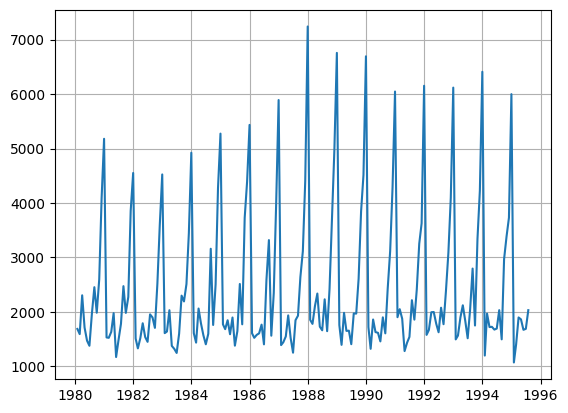

In [ ]:
## let's plot the sparkling vs timestamp
plt.plot(df);
plt.grid()

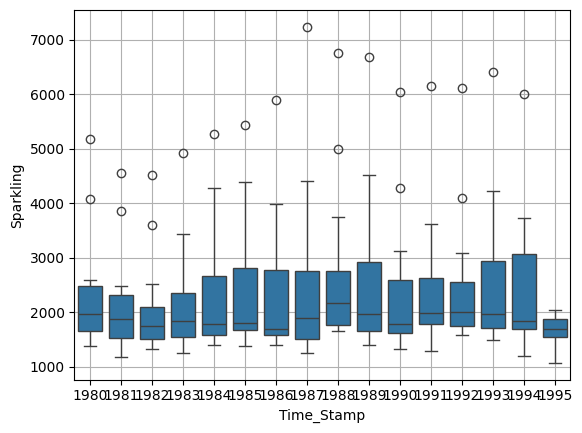

In [ ]:
sns.boxplot(x = df.index.year,y = df['Sparkling']) # Complete the code to check the relationship between the 'Sparkling' column and 'Time_Stamp'
plt.grid();

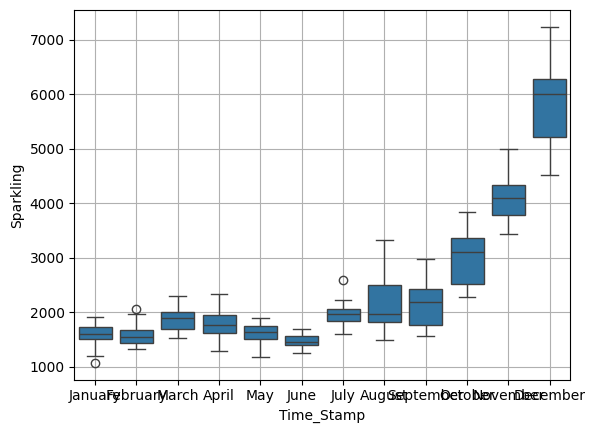

In [ ]:
sns.boxplot(x = df.index.month_name(),y = df['Sparkling']) # Complete the code to check the relationship between the 'Sparkling' column and 'Time_Stamp'
plt.grid();

### Decomposition

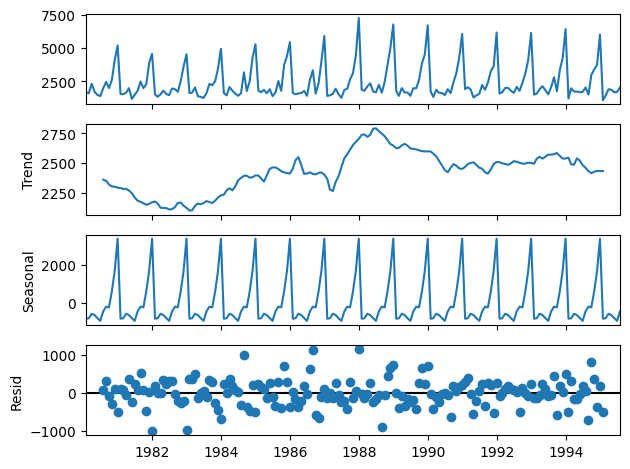

In [ ]:
decomposition = seasonal_decompose(df,model='additive') ##Complete the code to check additive Decomposition
decomposition.plot();

In [ ]:
trend = decomposition.trend
seasonality = decomposition.seasonal
residual = decomposition.resid

print('Trend','\n',trend.head(12),'\n')
print('Seasonality','\n',seasonality.head(12),'\n')
print('Residual','\n',residual.head(12),'\n')

Trend 
 Time_Stamp
1980-01-31            NaN
1980-02-29            NaN
1980-03-31            NaN
1980-04-30            NaN
1980-05-31            NaN
1980-06-30            NaN
1980-07-31    2360.666667
1980-08-31    2351.333333
1980-09-30    2320.541667
1980-10-31    2303.583333
1980-11-30    2302.041667
1980-12-31    2293.791667
Name: trend, dtype: float64 

Seasonality 
 Time_Stamp
1980-01-31    -854.260599
1980-02-29    -830.350678
1980-03-31    -592.356630
1980-04-30    -658.490559
1980-05-31    -824.416154
1980-06-30    -967.434011
1980-07-31    -465.502265
1980-08-31    -214.332821
1980-09-30    -254.677265
1980-10-31     599.769957
1980-11-30    1675.067179
1980-12-31    3386.983846
Name: seasonal, dtype: float64 

Residual 
 Time_Stamp
1980-01-31           NaN
1980-02-29           NaN
1980-03-31           NaN
1980-04-30           NaN
1980-05-31           NaN
1980-06-30           NaN
1980-07-31     70.835599
1980-08-31    315.999487
1980-09-30    -81.864401
1980-10-31   -307.3532

### Checking for additive assumptions

In [ ]:
residual.mean()

np.float64(-1.2088458994707376)

/tmp/ipykernel_482/2194742101.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(residual)


<Axes: xlabel='resid', ylabel='Density'>

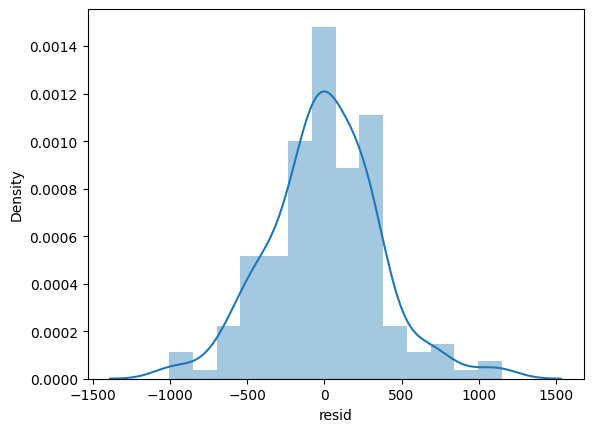

In [ ]:
##Normality Distribution of Resid
from scipy.stats import shapiro

sns.distplot(residual)

In [ ]:
shapiro(residual.dropna())

ShapiroResult(statistic=np.float64(0.9833056372432126), pvalue=np.float64(0.03433683203800602))

### Multiplicative Decomposition


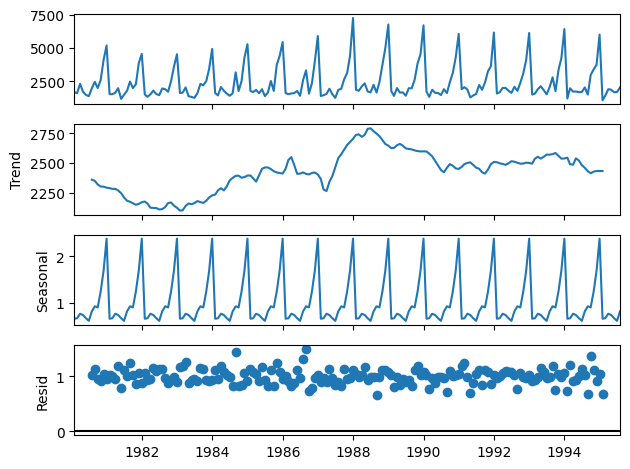

In [ ]:
#Multiplicative Decomposition
decomposition = seasonal_decompose(df,model='multiplicative') # complete the code to multiplicative decomposition
decomposition.plot();

In [ ]:
trend = decomposition.trend
seasonality = decomposition.seasonal
residual = decomposition.resid

print('Trend','\n',trend.head(12),'\n')
print('Seasonality','\n',seasonality.head(12),'\n')
print('Residual','\n',residual.head(12),'\n')

Trend 
 Time_Stamp
1980-01-31            NaN
1980-02-29            NaN
1980-03-31            NaN
1980-04-30            NaN
1980-05-31            NaN
1980-06-30            NaN
1980-07-31    2360.666667
1980-08-31    2351.333333
1980-09-30    2320.541667
1980-10-31    2303.583333
1980-11-30    2302.041667
1980-12-31    2293.791667
Name: trend, dtype: float64 

Seasonality 
 Time_Stamp
1980-01-31    0.649843
1980-02-29    0.659214
1980-03-31    0.757440
1980-04-30    0.730351
1980-05-31    0.660609
1980-06-30    0.603468
1980-07-31    0.809164
1980-08-31    0.918822
1980-09-30    0.894367
1980-10-31    1.241789
1980-11-30    1.690158
1980-12-31    2.384776
Name: seasonal, dtype: float64 

Residual 
 Time_Stamp
1980-01-31         NaN
1980-02-29         NaN
1980-03-31         NaN
1980-04-30         NaN
1980-05-31         NaN
1980-06-30         NaN
1980-07-31    1.029230
1980-08-31    1.135407
1980-09-30    0.955954
1980-10-31    0.907513
1980-11-30    1.050423
1980-12-31    0.946770
Name: r

### Checking for Multiplicative assumptions

In [ ]:
residual = decomposition.resid
residual.mean()

np.float64(0.9997456359115032)

/tmp/ipykernel_482/1108040850.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(residual)


<Axes: xlabel='resid', ylabel='Density'>

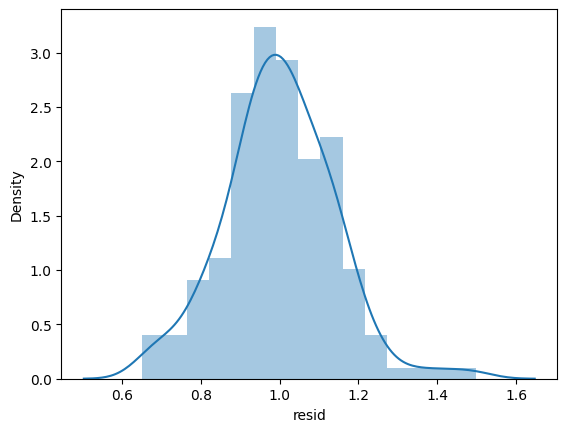

In [ ]:
sns.distplot(residual)

In [ ]:
shapiro(residual.dropna())

ShapiroResult(statistic=np.float64(0.9859993833004654), pvalue=np.float64(0.07803310394786477))

In [ ]:
df.describe()

,Sparkling
count,187.000000
mean,2402.417112
std,1295.111540
min,1070.000000
25%,1605.000000
50%,1874.000000
75%,2549.000000
max,7242.000000


## Data Preparation for Modeling


In [ ]:
df.index.year.unique()  ## Complete the code to check the unique values

Index([1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991,
       1992, 1993, 1994, 1995],
      dtype='int32', name='Time_Stamp')

In [ ]:
### Complete the code to take all data till the year 1991 in the train set and everything after that in the test set
df_train = df[df.index <= "1991-12-31"]
df_test = df[df.index > "1991-12-31"]

In [ ]:
print(df_train.shape)
print(df_test.shape)

(144, 1)
(43, 1)


#### Let's check the train dataset

In [ ]:
df_train.head()

,Sparkling
Time_Stamp,
1980-01-31,1686
1980-02-29,1591
1980-03-31,2304
1980-04-30,1712
1980-05-31,1471


#### Let's check the test dataset

In [ ]:
df_test.head()

,Sparkling
Time_Stamp,
1992-01-31,1577
1992-02-29,1667
1992-03-31,1993
1992-04-30,1997
1992-05-31,1783


## Model Building

### Linear Regression Model

- For this particular linear regression, we are going to regress the 'Sparkling' variable against the order of the occurrence.
- For this we need to modify our training data before fitting it into a linear regression.

In [ ]:
train_time = [i+1 for i in range(len(df_train))]
test_time = [i+133 for i in range(len(df_test))]
print('Training Time instance','\n',train_time)
print('Test Time instance','\n',test_time)

Training Time instance 
 [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144]
Test Time instance 
 [133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175]


In [ ]:
LinearRegression_train = df_train.copy()
LinearRegression_test = df_test.copy()

In [ ]:
LinearRegression_train['time'] = train_time
LinearRegression_test['time'] = test_time

print('First few rows of Training Data','\n',LinearRegression_train.head(),'\n')
print('Last few rows of Training Data','\n',LinearRegression_train.tail(),'\n')
print('First few rows of Test Data','\n',LinearRegression_test.head(),'\n')
print('Last few rows of Test Data','\n',LinearRegression_test.tail(),'\n')

First few rows of Training Data 
             Sparkling  time
Time_Stamp                 
1980-01-31       1686     1
1980-02-29       1591     2
1980-03-31       2304     3
1980-04-30       1712     4
1980-05-31       1471     5 

Last few rows of Training Data 
             Sparkling  time
Time_Stamp                 
1991-08-31       1857   140
1991-09-30       2408   141
1991-10-31       3252   142
1991-11-30       3627   143
1991-12-31       6153   144 

First few rows of Test Data 
             Sparkling  time
Time_Stamp                 
1992-01-31       1577   133
1992-02-29       1667   134
1992-03-31       1993   135
1992-04-30       1997   136
1992-05-31       1783   137 

Last few rows of Test Data 
             Sparkling  time
Time_Stamp                 
1995-03-31       1897   171
1995-04-30       1862   172
1995-05-31       1670   173
1995-06-30       1688   174
1995-07-31       2031   175 



In [ ]:
lr = LinearRegression()

In [ ]:
LinearRegression_train['Sparkling'].values

array([1686, 1591, 2304, 1712, 1471, 1377, 1966, 2453, 1984, 2596, 4087,
       5179, 1530, 1523, 1633, 1976, 1170, 1480, 1781, 2472, 1981, 2273,
       3857, 4551, 1510, 1329, 1518, 1790, 1537, 1449, 1954, 1897, 1706,
       2514, 3593, 4524, 1609, 1638, 2030, 1375, 1320, 1245, 1600, 2298,
       2191, 2511, 3440, 4923, 1609, 1435, 2061, 1789, 1567, 1404, 1597,
       3159, 1759, 2504, 4273, 5274, 1771, 1682, 1846, 1589, 1896, 1379,
       1645, 2512, 1771, 3727, 4388, 5434, 1606, 1523, 1577, 1605, 1765,
       1403, 2584, 3318, 1562, 2349, 3987, 5891, 1389, 1442, 1548, 1935,
       1518, 1250, 1847, 1930, 2638, 3114, 4405, 7242, 1853, 1779, 2108,
       2336, 1728, 1661, 2230, 1645, 2421, 3740, 4988, 6757, 1757, 1394,
       1982, 1650, 1654, 1406, 1971, 1968, 2608, 3845, 4514, 6694, 1720,
       1321, 1859, 1628, 1615, 1457, 1899, 1605, 2424, 3116, 4286, 6047,
       1902, 2049, 1874, 1279, 1432, 1540, 2214, 1857, 2408, 3252, 3627,
       6153])

In [ ]:
lr.fit(LinearRegression_train[['time']],LinearRegression_train['Sparkling'].values)

LinearRegression()

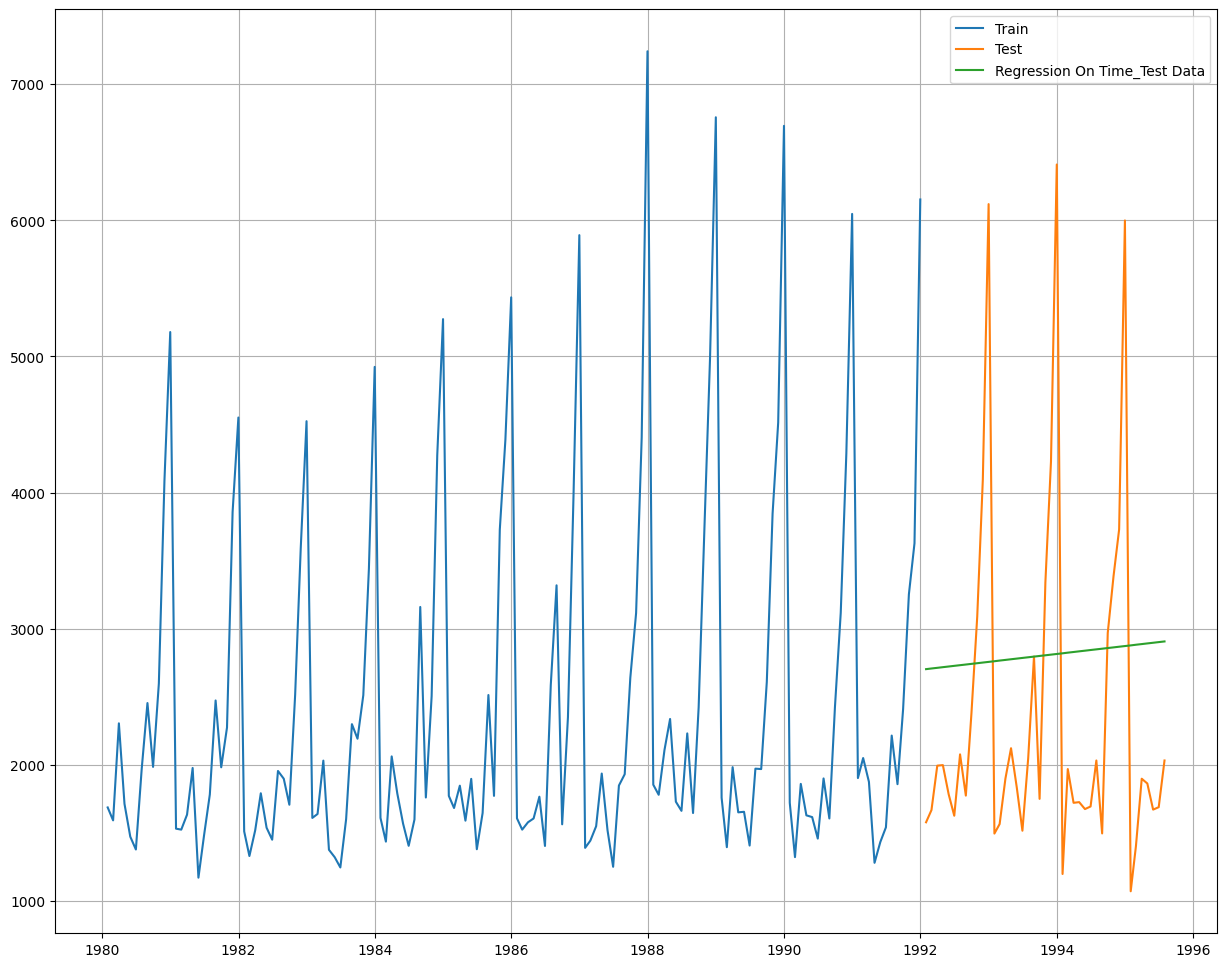

In [ ]:
test_prediction_model = lr.predict(LinearRegression_test[['time']])
LinearRegression_test['RegOnTime']=test_prediction_model

plt.figure(figsize=(15,12))
plt.plot(df_train['Sparkling'],label='Train')
plt.plot(df_test['Sparkling'],label='Test')
plt.plot(LinearRegression_test['RegOnTime'],label='Regression On Time_Test Data')
plt.legend(loc='best')
plt.grid();

In [ ]:
rmse_model_test= metrics.mean_squared_error(df_test['Sparkling'],test_prediction_model)
rmse_model_test = np.sqrt(rmse_model_test)
print("For RegressionOnTime forecast on the Test Data,  RMSE is %3.3f" %(rmse_model_test))

For RegressionOnTime forecast on the Test Data,  RMSE is 1337.090


In [ ]:
resultsDf = pd.DataFrame({'Test RMSE': [rmse_model_test]},index=['RegressionOnTime'])
resultsDf

,Test RMSE
RegressionOnTime,1337.09022


### Naive Approach Model

For this particular naive model, we say that the prediction for tomorrow is the same as today and the prediction for day after tomorrow is tomorrow and since the prediction of tomorrow is same as today,therefore the prediction for day after tomorrow is also today.

In [ ]:
NaiveModel_train = df_train.copy() # Complete the code to create a copy of the train datasets
NaiveModel_test = df_test.copy() # Complete the code to create a copy of the test datasets

In [ ]:
NaiveModel_train.shape

(144, 1)

In [ ]:
NaiveModel_test.shape

(43, 1)

In [ ]:
NaiveModel_test.head()

,Sparkling
Time_Stamp,
1992-01-31,1577
1992-02-29,1667
1992-03-31,1993
1992-04-30,1997
1992-05-31,1783


In [ ]:
NaiveModel_test['naive'] = np.asarray(df_train['Sparkling'])[len(np.asarray(df_train['Sparkling']))-1]
NaiveModel_test['naive'].head()

,naive
Time_Stamp,
1992-01-31,6153
1992-02-29,6153
1992-03-31,6153
1992-04-30,6153
1992-05-31,6153


In [ ]:
NaiveModel_test.head()

,Sparkling,naive
Time_Stamp,,
1992-01-31,1577,6153
1992-02-29,1667,6153
1992-03-31,1993,6153
1992-04-30,1997,6153
1992-05-31,1783,6153


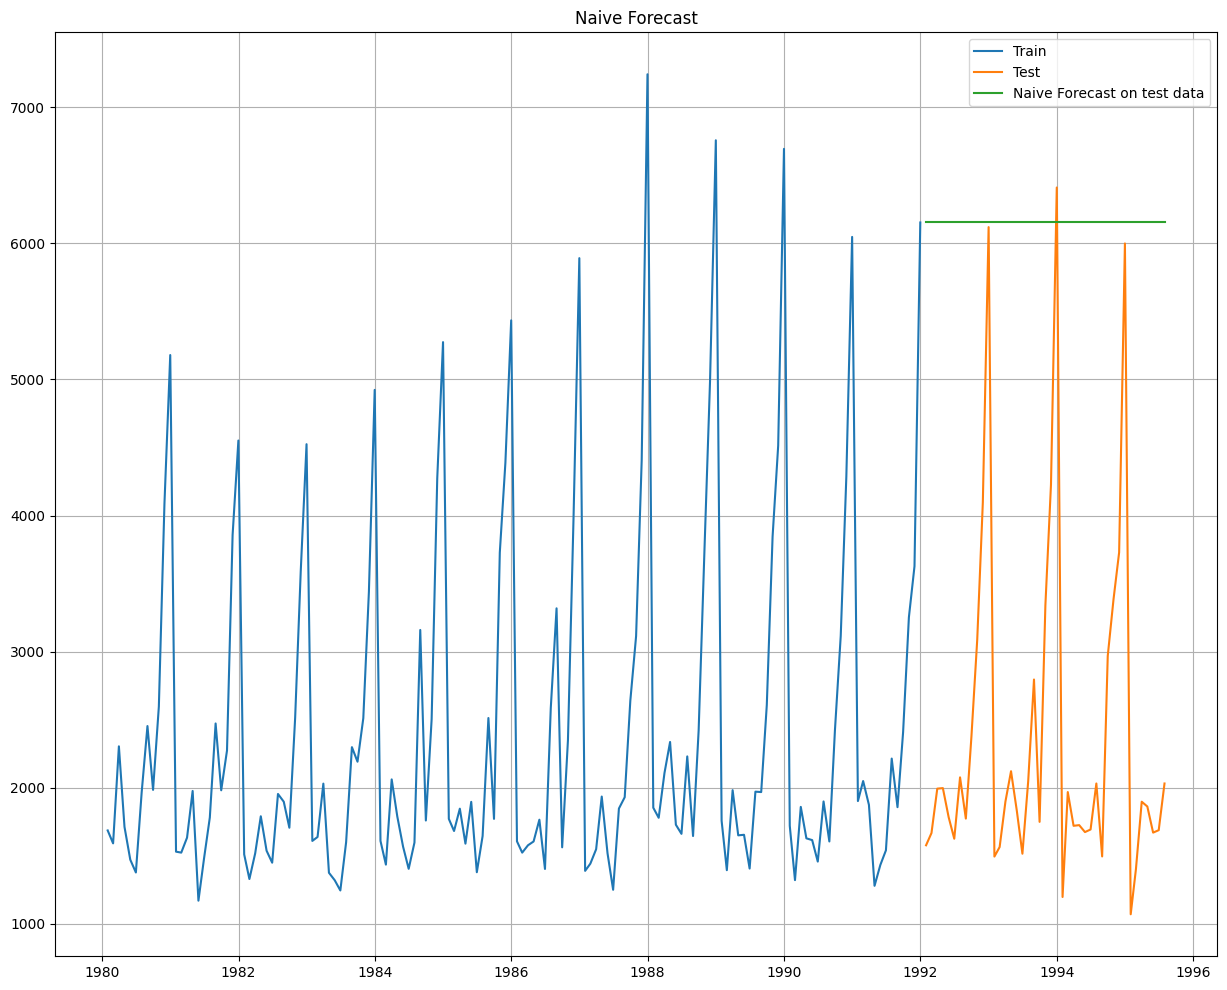

In [ ]:
plt.figure(figsize=(15,12))
plt.plot(NaiveModel_train['Sparkling'],label='Train')
plt.plot(df_test['Sparkling'],label='Test')
plt.plot(NaiveModel_test['naive'], label='Naive Forecast on test data')
plt.legend(loc='best')
plt.title('Naive Forecast')
plt.grid();

In [ ]:
##MODEL EVAULATION
rmse_model_test = metrics.mean_squared_error(df_test['Sparkling'],NaiveModel_test['naive'])
rmse_model_test = np.sqrt(rmse_model_test)
print("For Naive On Time Forecast on the Test Data, RMSE is %3.3f" %(rmse_model_test))

For Naive On Time Forecast on the Test Data, RMSE is 3979.915


In [ ]:
resultsDfN = pd.DataFrame({'Test RMSE': [rmse_model_test]}, index=['NaiveModel']) # Complete the code to check the perfromance of the 'NaiveModel'
resultsDf = pd.concat([resultsDf,resultsDfN])
resultsDf

,Test RMSE
RegressionOnTime,1337.09022
NaiveModel,1337.09022


### Simple Average Model

For this particular simple average method, we will forecast by using the average of the training values.

In [ ]:
# Let's create the copy of the train and test dataset
SimpleAverage_train = df_train.copy() # Complete the code to create a copy of the train datasets
SimpleAverage_test = df_test.copy() # Complete the code to create a copy of the test datasets

In [ ]:
SimpleAverage_test['mean forecast']= df_train['Sparkling'].mean()
SimpleAverage_test.head()

,Sparkling,mean forecast
Time_Stamp,,
1992-01-31,1577,2408.930556
1992-02-29,1667,2408.930556
1992-03-31,1993,2408.930556
1992-04-30,1997,2408.930556
1992-05-31,1783,2408.930556


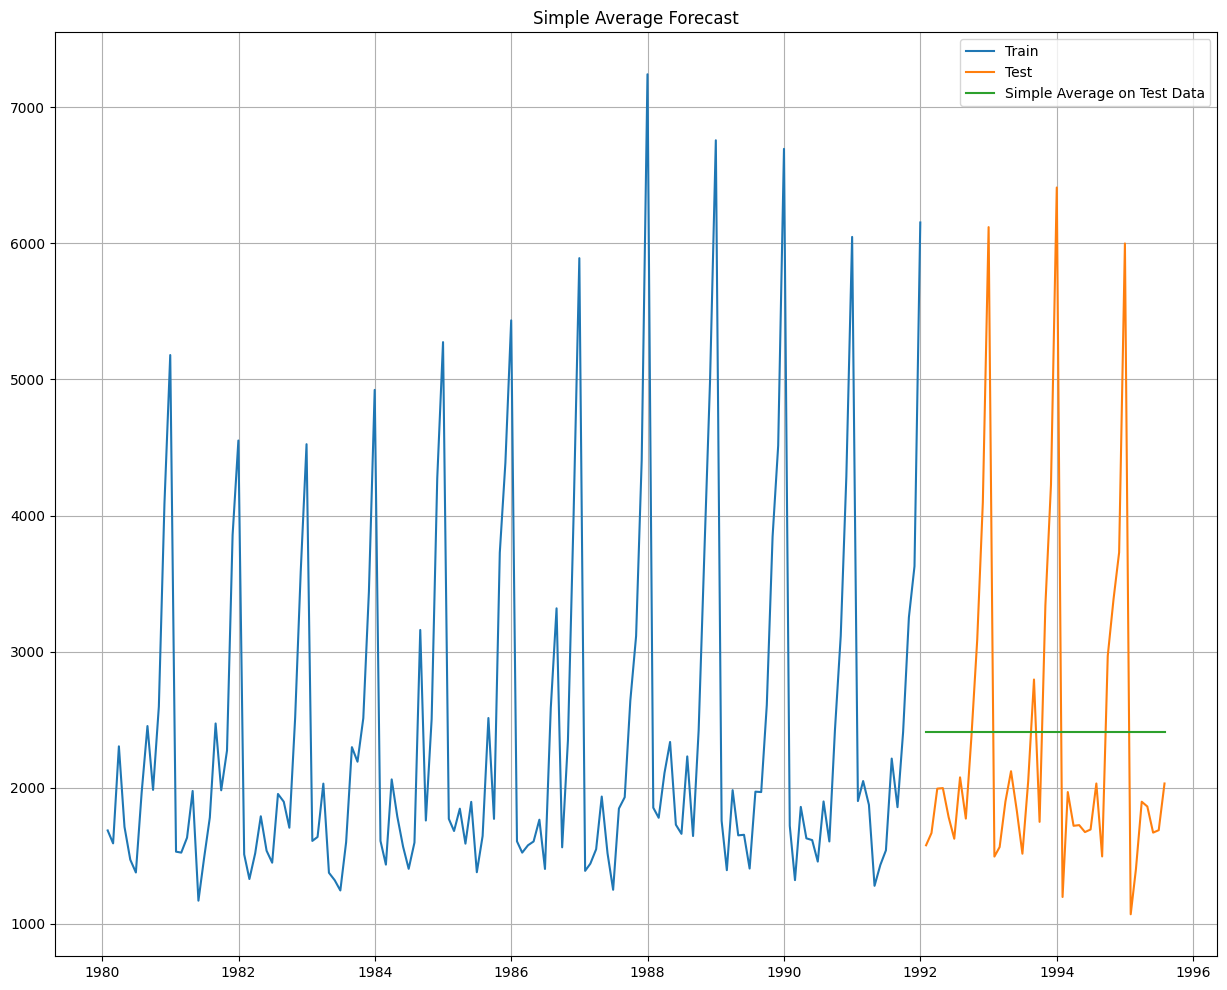

In [ ]:
plt.figure(figsize=(15,12))
plt.plot(df_train['Sparkling'],label='Train')
plt.plot(df_test['Sparkling'], label='Test')
plt.plot(SimpleAverage_test['mean forecast'],label='Simple Average on Test Data')
plt.legend(loc='best')
plt.title("Simple Average Forecast")
plt.grid();

In [ ]:
##MODEL EVAULATION
rmse_model_test = metrics.mean_squared_error(df_test['Sparkling'],SimpleAverage_test['mean forecast'])
rmse_model_test = np.sqrt(rmse_model_test)
print("For Simple Average Forecast on Test Data, RMSE is %3.3f"%(rmse_model_test))

For Simple Average Forecast on Test Data, RMSE is 1268.683


In [ ]:
resultsDfSES = pd.DataFrame({'Test RMSE':  [rmse_model_test]},index=['SimpleAverageModel']) # Complete the code to check the perfromance of the 'SimpleAverageModel'
resultsDf = pd.concat([resultsDf,resultsDfSES])

In [ ]:
resultsDf

,Test RMSE
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleAverageModel,1268.683035


### Simple Exponential Smoothing Model

In [ ]:
# Let's create the train and test dataset
SES_train = df_train.copy() # Complete the code to create a copy of the train datasets
SES_test =  df_test.copy() # Complete the code to create a copy of the test datasets

In [ ]:
model_SES = SimpleExpSmoothing(SES_train['Sparkling'])

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


In [ ]:
model_SES_autofit = model_SES.fit(optimized=True)

In [ ]:
model_SES_autofit.params

{'smoothing_level': np.float64(0.03667203108765097),
 'smoothing_trend': np.float64(nan),
 'smoothing_seasonal': np.float64(nan),
 'damping_trend': nan,
 'initial_level': np.float64(1686.0),
 'initial_trend': np.float64(nan),
 'initial_seasons': array([], dtype=float64),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

In [ ]:
SES_test['predict'] = model_SES_autofit.forecast(steps=len(df_test))

In [ ]:
SES_test.head()

,Sparkling,predict
Time_Stamp,,
1992-01-31,1577,2635.950609
1992-02-29,1667,2635.950609
1992-03-31,1993,2635.950609
1992-04-30,1997,2635.950609
1992-05-31,1783,2635.950609


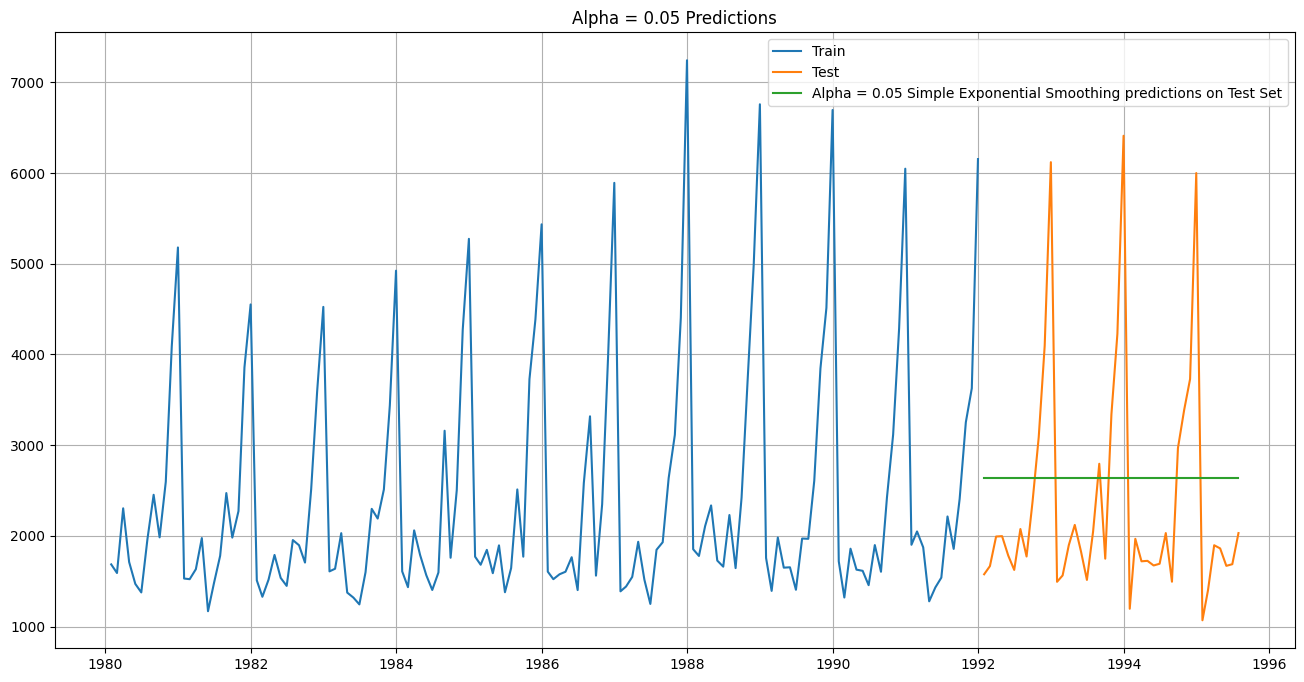

In [ ]:
## Plotting on both the Training and Test data

plt.figure(figsize=(16,8))
plt.plot(SES_train['Sparkling'], label='Train')
plt.plot(SES_test['Sparkling'], label='Test')

plt.plot(SES_test['predict'], label='Alpha = 0.05 Simple Exponential Smoothing predictions on Test Set')

plt.legend(loc='best')
plt.grid()
plt.title('Alpha = 0.05 Predictions');

#### Model Evaluation for  𝛼  = 0.05 : Simple Exponential Smoothing

In [ ]:
rmse_model_test = metrics.mean_squared_error(SES_test['Sparkling'],SES_test['predict'])
rmse_model_test = np.sqrt(rmse_model_test)
print("For Alpha = 0.05 SES Model on Test Data,RMSE is %3.3f" %(rmse_model_test))

For Alpha = 0.05 SES Model on Test Data,RMSE is 1293.814


In [ ]:
resultsDf_1 = pd.DataFrame({'Test RMSE': [rmse_model_test]},index=['SimpleExponentialSmoothing_Alpha_0.05'])   # Complete the code to check the perfromance of the 'Alpha = 0.05,SimpleExponentialSmoothing'
resultsDf = pd.concat([resultsDf, resultsDf_1])
resultsDf

,Test RMSE
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455


#### Setting different alpha values.


Remember, the higher the alpha value more weightage is given to the more recent observation. That means, what happened recently will happen again.
We will run a loop with different alpha values to understand which particular value works best for alpha on the test set.

First we will define an empty dataframe to store our values from the loop


In [ ]:
resultsDf_a = pd.DataFrame({'Alpha Values':[],'Train RMSE':[],'Test RMSE': []})
resultsDf_a

,Alpha Values,Train RMSE,Test RMSE


In [ ]:
resultsDf_a = pd.DataFrame({'Alpha Values':[],'Train RMSE':[],'Test RMSE': []})
for i in np.arange(0.3,1,0.1):
    model_SES_alpha_i = model_SES.fit(smoothing_level=i,optimized=False,use_brute=True)
    SES_train['predict',i] = model_SES_alpha_i.fittedvalues
    SES_test['predict',i] = model_SES_alpha_i.forecast(steps=len(df_test))

    rmse_model5_train_i = np.sqrt(metrics.mean_squared_error(SES_train['Sparkling'],SES_train['predict',i]))

    rmse_model5_test_i = np.sqrt(metrics.mean_squared_error(SES_test['Sparkling'],SES_test['predict',i]))

    resultsDf_a = resultsDf_a._append({'Alpha Values':i,'Train RMSE':rmse_model5_train_i
                                      ,'Test RMSE':rmse_model5_test_i}, ignore_index=True)

In [ ]:
resultsDf_a.sort_values(by=['Test RMSE'],ascending=True)

,Alpha Values,Train RMSE,Test RMSE
0,0.3,1362.731346,1900.058569
1,0.4,1356.208919,2260.069389
2,0.5,1347.944758,2606.296390
3,0.6,1343.099607,2924.118301
4,0.7,1343.640190,3214.744366
5,0.8,1349.991473,3483.731806
6,0.9,1362.270034,3736.981096


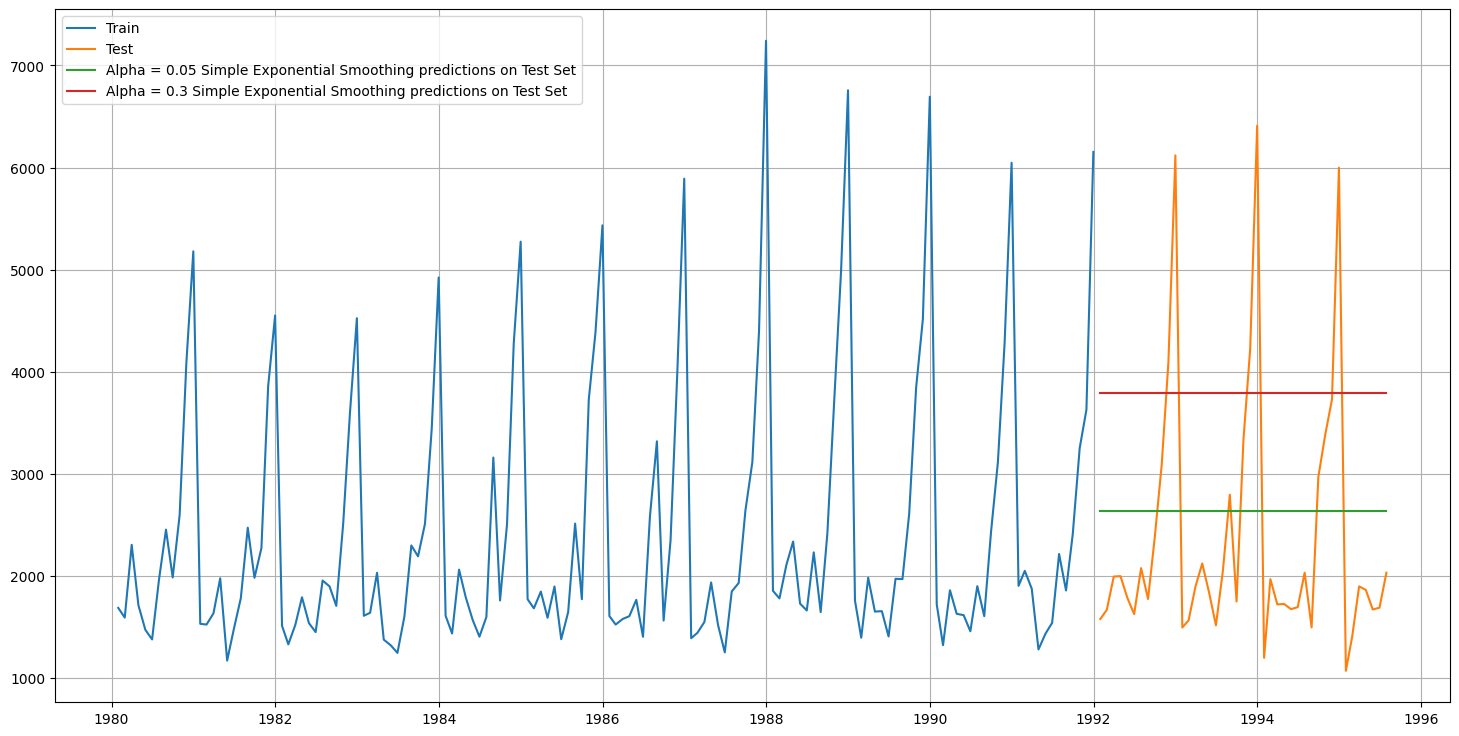

In [ ]:
## Plotting on both the Training and Test data

plt.figure(figsize=(18,9))
plt.plot(SES_train['Sparkling'], label='Train')
plt.plot(SES_test['Sparkling'], label='Test')

plt.plot(SES_test['predict'], label='Alpha = 0.05 Simple Exponential Smoothing predictions on Test Set')

plt.plot(SES_test['predict', 0.3], label='Alpha = 0.3 Simple Exponential Smoothing predictions on Test Set')



plt.legend(loc='best')
plt.grid();

In [ ]:
resultsDf_2 = pd.DataFrame({'Test RMSE': [resultsDf_a.sort_values(by=['Test RMSE'],ascending=True).values[0][2]]}
                           ,index=['SimpleExponentialSmoothing_Best_Alpha'])
resultsDf = pd.concat([resultsDf, resultsDf_2])
resultsDf

,Test RMSE
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455
SimpleExponentialSmoothing_Best_Alpha,1900.058569


### Double Exponential Smoothing (Holt's Model)

Two parameters  𝛼  and  𝛽  are estimated in this model. Level and Trend are accounted for in this model.

In [ ]:
DES_train = df_train.copy() # Complete the code to create a copy of the train dataset
DES_test = df_test.copy() # Complete the code to create a copy of the test dataset

In [ ]:
model_DES = Holt(DES_train['Sparkling'])

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


In [ ]:
model_DES_autofit = model_DES.fit()

In [ ]:
model_DES_autofit.params

{'smoothing_level': np.float64(0.6678921248101082),
 'smoothing_trend': np.float64(0.00567583364200997),
 'smoothing_seasonal': np.float64(nan),
 'damping_trend': nan,
 'initial_level': np.float64(1686.0),
 'initial_trend': np.float64(-95.0),
 'initial_seasons': array([], dtype=float64),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

In [ ]:
DES_test.shape

(43, 1)

In [ ]:
## Prediction on the test data

DES_test['auto_predict'] = model_DES_autofit.forecast(steps=len(df_test))
DES_test.head()

,Sparkling,auto_predict
Time_Stamp,,
1992-01-31,1577,5193.610144
1992-02-29,1667,5169.598791
1992-03-31,1993,5145.587438
1992-04-30,1997,5121.576085
1992-05-31,1783,5097.564731


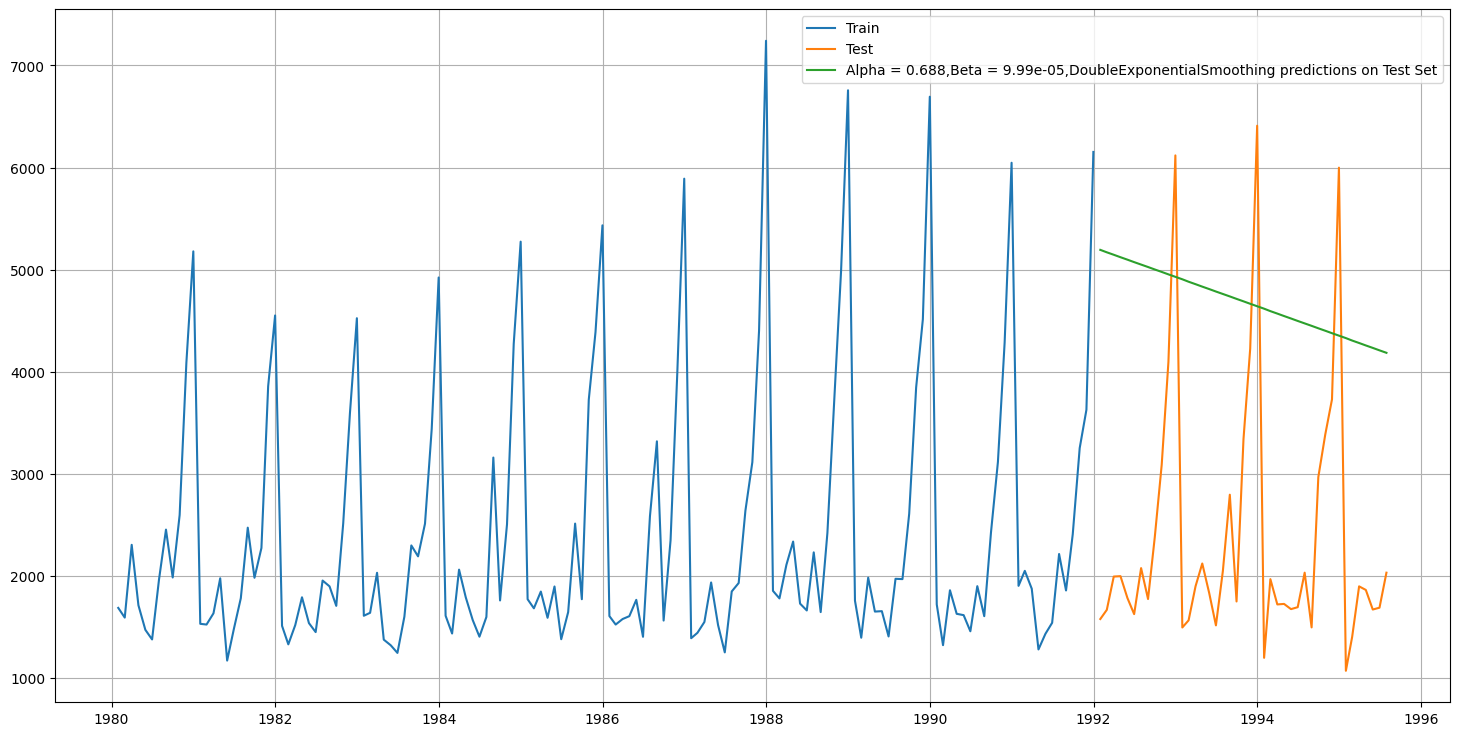

In [ ]:
## Plotting on both the Training and Test using autofit

plt.figure(figsize=(18,9))
plt.plot(DES_train['Sparkling'], label='Train')
plt.plot(DES_test['Sparkling'], label='Test')

plt.plot(DES_test['auto_predict'], label='Alpha = 0.688,Beta = 9.99e-05,DoubleExponentialSmoothing predictions on Test Set')


plt.legend(loc='best')
plt.grid();

In [ ]:
## Test Data

rmse_model_test = metrics.mean_squared_error(DES_test['Sparkling'],DES_test['auto_predict'])
rmse_model_test = np.sqrt(rmse_model_test)
print("For Alpha=0.688,Beta=0.00009,DoubleExponentialSmoothing predictions on Test Data,  RMSE is %3.3f" %(rmse_model_test))

For Alpha=0.688,Beta=0.00009,DoubleExponentialSmoothing predictions on Test Data,  RMSE is 2654.534


In [ ]:
resultsDf_DES = pd.DataFrame({'Test RMSE': [rmse_model_test]}
                           ,index=['DoubleExponentialSmoothing_AutoFit'])  # Complete the code to check the perfromance of the 'Alpha=0.688,Beta=0.00009,DoubleExponentialSmoothing'

resultsDf = pd.concat([resultsDf, resultsDf_DES])
resultsDf

,Test RMSE
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455
SimpleExponentialSmoothing_Best_Alpha,1900.058569
DoubleExponentialSmoothing_AutoFit,2654.533701


In [ ]:
## First we will define an empty dataframe to store our values from the loop

resultsDf_b = pd.DataFrame({'Alpha Values':[],'Beta Values':[],'Train RMSE':[],'Test RMSE': []})
resultsDf_b

,Alpha Values,Beta Values,Train RMSE,Test RMSE


In [ ]:
len(df_test)

43

In [ ]:
for i in np.arange(0.3,1.1,0.1):
    for j in np.arange(0.3,1.1,0.1):
        model_DES_alpha_i_j = model_DES.fit(smoothing_level=i,smoothing_trend=j,optimized=False,use_brute=True)
        DES_train['predict',i,j] = model_DES_alpha_i_j.fittedvalues
        DES_test['predict',i,j] = model_DES_alpha_i_j.forecast(steps=len(df_test))

        rmse_model_train = np.sqrt(metrics.mean_squared_error(DES_train['Sparkling'],DES_train['predict',i,j]))

        rmse_model_test = np.sqrt(metrics.mean_squared_error(DES_test['Sparkling'],DES_test['predict',i,j]))

        resultsDf_b = resultsDf_b._append({'Alpha Values':i,'Beta Values':j,'Train RMSE':rmse_model_train
                                          ,'Test RMSE':rmse_model_test}, ignore_index=True)

In [ ]:
resultsDf_b.sort_values(by=['Test RMSE']).head()

,Alpha Values,Beta Values,Train RMSE,Test RMSE
0,0.3,0.3,1599.398181,13814.398308
8,0.4,0.3,1578.236948,18044.669982
1,0.3,0.4,1693.819564,19249.257218
16,0.5,0.3,1538.865716,20684.637333
24,0.6,0.3,1513.676637,22536.689632


In [ ]:
DES_test.columns

Index([                                        'Sparkling',
                                            'auto_predict',
                                     ('predict', 0.3, 0.3),
                                     ('predict', 0.3, 0.4),
                                     ('predict', 0.3, 0.5),
                      ('predict', 0.3, 0.6000000000000001),
                      ('predict', 0.3, 0.7000000000000002),
                      ('predict', 0.3, 0.8000000000000003),
                      ('predict', 0.3, 0.9000000000000001),
                      ('predict', 0.3, 1.0000000000000002),
                                     ('predict', 0.4, 0.3),
                                     ('predict', 0.4, 0.4),
                                     ('predict', 0.4, 0.5),
                      ('predict', 0.4, 0.6000000000000001),
                      ('predict', 0.4, 0.7000000000000002),
                      ('predict', 0.4, 0.8000000000000003),
                      ('predict', 0.4, 0

In [ ]:
resultsDf_3 = pd.DataFrame({'Test RMSE': [resultsDf_b.sort_values(by=['Test RMSE']).values[0][3]]}
                           ,index=['Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing'])   # Complete the code to check the perfromance of the 'Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing'

resultsDf = pd.concat([resultsDf, resultsDf_3])
resultsDf

,Test RMSE
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455
SimpleExponentialSmoothing_Best_Alpha,1900.058569
DoubleExponentialSmoothing_AutoFit,2654.533701
"Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing",13814.398308


### Triple Exponential Smoothing (Holt - Winter's Model)

Three parameters  𝛼 ,  𝛽  and  𝛾  are estimated in this model. Level, Trend and Seasonality are accounted for in this model.

In [ ]:
# Creating the copy of train and test dataset
TES_train = df_train.copy() # Complete the code to create a copy of the train dataset
TES_test = df_test.copy() # Complete the code to create a copy of the test dataset

In [ ]:
model_TES = ExponentialSmoothing(TES_train['Sparkling'],trend='additive',seasonal='multiplicative',freq='M')

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:595: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  freq = to_offset(freq)


In [ ]:
model_TES_autofit = model_TES.fit()

In [ ]:
model_TES_autofit.params

{'smoothing_level': np.float64(0.07491295595488828),
 'smoothing_trend': np.float64(0.07491295595488828),
 'smoothing_seasonal': np.float64(0.2833959688663245),
 'damping_trend': nan,
 'initial_level': np.float64(2356.5020981873167),
 'initial_trend': np.float64(-19.55614396441527),
 'initial_seasons': array([0.69642481, 0.66263147, 0.8661978 , 0.78371893, 0.6409794 ,
        0.62710199, 0.86203455, 1.11207461, 0.90589561, 1.22639337,
        1.87827821, 2.43148971]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

In [ ]:
##PREDICTION ON TEST SET
TES_test['auto_predict'] = model_TES_autofit.forecast(steps=len(df_test))
TES_test.head()

,Sparkling,auto_predict
Time_Stamp,,
1992-01-31,1577,1699.806254
1992-02-29,1667,1588.100259
1992-03-31,1993,1797.378411
1992-04-30,1997,1568.061775
1992-05-31,1783,1518.346802


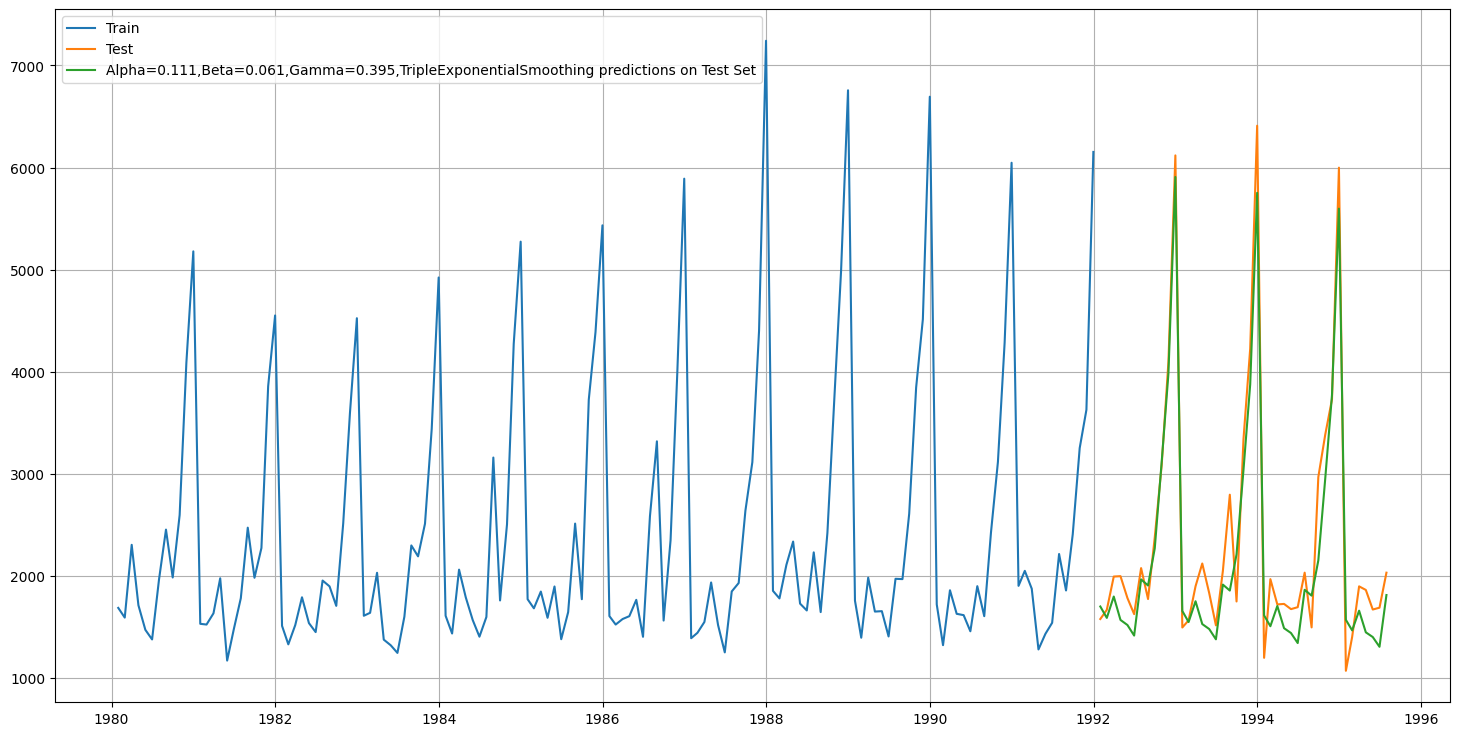

In [ ]:
## Plotting on both the Training and Test using autofit

plt.figure(figsize=(18,9))
plt.plot(TES_train['Sparkling'], label='Train')
plt.plot(TES_test['Sparkling'], label='Test')

plt.plot(TES_test['auto_predict'], label='Alpha=0.111,Beta=0.061,Gamma=0.395,TripleExponentialSmoothing predictions on Test Set')


plt.legend(loc='best')
plt.grid();

In [ ]:
## Test Data

rmse_model_test = np.sqrt(metrics.mean_squared_error(TES_test['Sparkling'],TES_test['auto_predict']))
print("Alpha=0.111,Beta=0.061,Gamma=0.395,TripleExponentialSmoothing predictions on Test Set,  RMSE is %3.3f" %(rmse_model_test))

Alpha=0.111,Beta=0.061,Gamma=0.395,TripleExponentialSmoothing predictions on Test Set,  RMSE is 350.053


In [ ]:
## First we will define an empty dataframe to store our values from the loop
resultsDf_c = pd.DataFrame({'Alpha Values':[],'Beta Values':[],'Gamma Values':[],'Train RMSE':[],'Test RMSE': []})
resultsDf_c

,Alpha Values,Beta Values,Gamma Values,Train RMSE,Test RMSE


In [ ]:
train_prediction_dfs = [] # List to hold single-column DataFrames of predictions
test_prediction_dfs = []  # List to hold single-column DataFrames of predictions
results_data_for_df_c = [] # List of dictionaries for resultsDf_c

for i in np.arange(0.3,1.1,0.1):
    for j in np.arange(0.3,1.1,0.1):
        for k in np.arange(0.3,1.1,0.1):
            model_TES_alpha_i_j_k = model_TES.fit(smoothing_level=i,smoothing_trend=j,smoothing_seasonal=k,optimized=False,use_brute=True)

            # Create Series for current iteration's predictions
            current_train_predictions = pd.Series(model_TES_alpha_i_j_k.fittedvalues, index=TES_train.index, name=('predict',i,j,k))
            current_test_predictions = pd.Series(model_TES_alpha_i_j_k.forecast(steps=len(df_test)), index=TES_test.index, name=('predict',i,j,k))

            # Append as single-column DataFrames to the lists
            train_prediction_dfs.append(current_train_predictions.to_frame())
            test_prediction_dfs.append(current_test_predictions.to_frame())

            # Calculate RMSE using the Series
            rmse_model_train = np.sqrt(metrics.mean_squared_error(TES_train['Sparkling'], current_train_predictions))
            rmse_model_test = np.sqrt(metrics.mean_squared_error(TES_test['Sparkling'], current_test_predictions))

            # Append results to the list for resultsDf_c
            results_data_for_df_c.append({'Alpha Values':i,'Beta Values':j,'Gamma Values':k,
                                          'Train RMSE':rmse_model_train,'Test RMSE':rmse_model_test})

# After the loops, concatenate all collected prediction DataFrames
if train_prediction_dfs:
    # Concatenate all prediction columns with the original 'Sparkling' column
    TES_train = pd.concat([TES_train['Sparkling'].to_frame()] + train_prediction_dfs, axis=1)
if test_prediction_dfs:
    TES_test = pd.concat([TES_test['Sparkling'].to_frame()] + test_prediction_dfs, axis=1)

# Recreate resultsDf_c once from the list of dictionaries
resultsDf_c = pd.DataFrame(results_data_for_df_c)

/tmp/ipykernel_482/3862040566.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  TES_test['predict',i,j,k] = model_TES_alpha_i_j_k.forecast(steps=len(df_test))
/tmp/ipykernel_482/3862040566.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  TES_train['predict',i,j,k] = model_TES_alpha_i_j_k.fittedvalues
/tmp/ipykernel_482/3862040566.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using p

In [ ]:
resultsDf_c.sort_values(by=['Test RMSE']).head()

,Alpha Values,Beta Values,Gamma Values,Train RMSE,Test RMSE
128,0.5,0.3,0.3,448.489627,412.613756
194,0.6,0.3,0.5,541.879579,478.752553
72,0.4,0.4,0.3,451.720449,485.608082
260,0.7,0.3,0.7,726.763349,561.382299
81,0.4,0.5,0.4,508.681964,579.245326


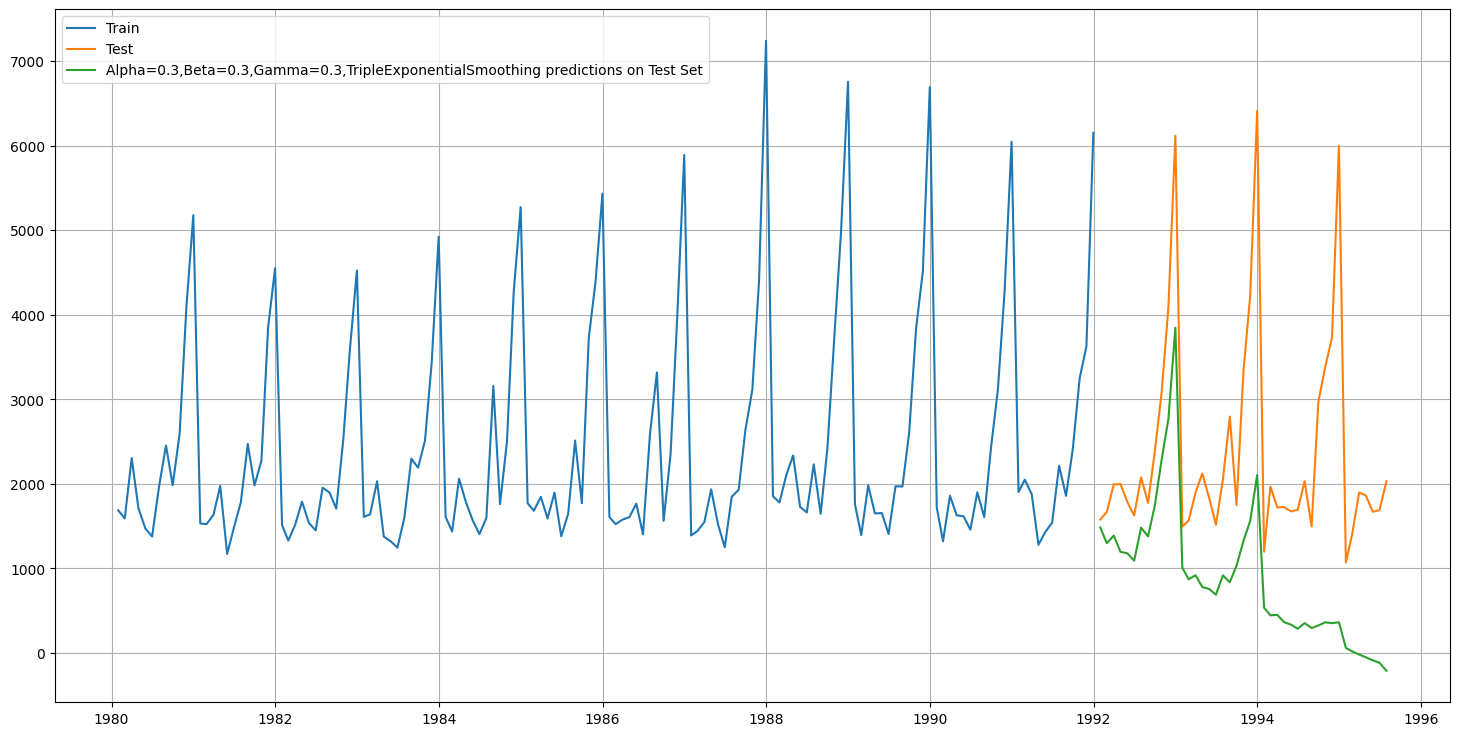

In [ ]:
## Plotting on both the Training and Test data using brute force alpha, beta and gamma determination

plt.figure(figsize=(18,9))
plt.plot(TES_train['Sparkling'], label='Train')
plt.plot(TES_test['Sparkling'], label='Test')

#The value of alpha and beta is taken like that by python
plt.plot(TES_test['predict', 0.3, 0.3, 0.3], label='Alpha=0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing predictions on Test Set')


plt.legend(loc='best')
plt.grid();

In [ ]:
resultsDf_2 = pd.DataFrame({'Test RMSE': [resultsDf_c.sort_values(by=['Test RMSE']).values[0][4]]}
                           ,index=['Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing'])  # Complete the code to check the perfromance of the 'Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing'


resultsDf = pd.concat([resultsDf, resultsDf_2])
resultsDf

,Test RMSE
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455
SimpleExponentialSmoothing_Best_Alpha,1900.058569
DoubleExponentialSmoothing_AutoFit,2654.533701
"Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing",13814.398308
"Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing",412.613756


In [ ]:
resultsDf1 = resultsDf.sort_values(by=['Test RMSE'])
resultsDf1

,Test RMSE
"Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing",412.613756
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455
NaiveModel,1337.090220
RegressionOnTime,1337.090220
SimpleExponentialSmoothing_Best_Alpha,1900.058569
DoubleExponentialSmoothing_AutoFit,2654.533701
"Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing",13814.398308


### Checking for Stationarity

Let's check for the stationarity of the data on which the model is being built on using appropriate statistical tests and also mention the hypothesis for the statistical test. If the data is found to be non-stationary, take appropriate steps to make it stationary. Check the new data for stationarity and comment. Note: Stationarity should be checked at alpha = 0.05.

In [ ]:
from statsmodels.tsa.stattools import adfuller
def test_stationarity(timeseries):

    #determining roll statistics
    rolmean = timeseries.rolling(window=12).mean()
    rolstd = timeseries.rolling(window=12).std()

    ##plot rolling Statistics:
    orig = plt.plot(timeseries,color='blue',label='Original')
    mean = plt.plot(rolmean, color='red', label='Rolling Mean')
    std = plt.plot(rolstd, color='black', label='Rolling Std')
    plt.legend(loc='best')
    plt.title('Rolling Mean and Standard Deviation')
    plt.show(block=False)

    #Perform Dickey-Fuller Test:
    print('Results of Dickey Fuller Test:')
    dftest = adfuller(timeseries, autolag='AIC')
    dfoutput = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    for key,value in dftest[4].items():
        dfoutput['Critical Value (%s)'%key] = value
    print(dfoutput,'\n')

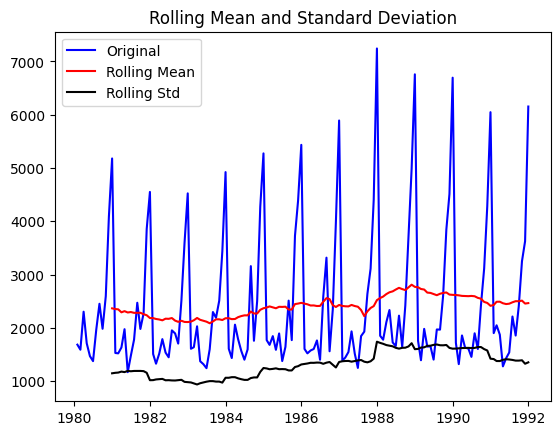

Results of Dickey Fuller Test:
Test Statistic                  -1.265771
p-value                          0.644683
#Lags Used                      12.000000
Number of Observations Used    131.000000
Critical Value (1%)             -3.481282
Critical Value (5%)             -2.883868
Critical Value (10%)            -2.578677
dtype: float64 



In [ ]:
test_stationarity(df_train['Sparkling'])

**Write the Observations**

H0 : The series is not stationary

Ha: The series is Stationary

- autolag{“AIC”, “BIC”, “t-stat”, None}
Method to use when automatically determining the lag length among the values 0, 1, …, maxlag.

- If “AIC” (default) or “BIC”, then the number of lags is chosen to minimize the corresponding information criterion.

- “t-stat” based choice of maxlag. Starts with maxlag and drops a lag until the t-statistic on the last lag length is significant using a 5%-sized test.

- If None, then the number of included lags is set to maxlag.


- The null hypothesis of the Augmented Dickey-Fuller is that there is a unit root, with the alternative that there is no unit root. If the pvalue is above a critical size, then we cannot reject that there is a unit root.

Stationary TS allow us to essentially have copies of things which enables us to build appropriate statistical models for forecasting

LETS BUILD IT ON DF_TRAIN MODEL

In [ ]:
dftest = adfuller(df_train.diff().dropna(),regression='ct')
print('DF test statistics is %3.3f' %dftest[0])
print('DF test p-value is', dftest[1])
print('DF test p-value is', dftest[2])

DF test statistics is -8.628
DF test p-value is 2.5490597847949586e-12
DF test p-value is 11


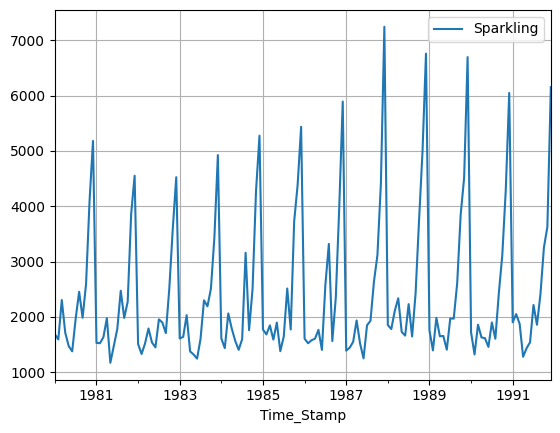

In [ ]:
df_train.plot(grid=True);

### Automated ARIMA Model based on lowest AIC

Let's build an automated version of the ARIMA model in which the parameters are selected using the lowest Akaike Information Criteria (AIC) on the training data and evaluate this model on the test data using RMSE.

In [ ]:
import itertools
p = q = range(0,4)
d = range(1,2)
pdq = list(itertools.product(p,d,q))
print('Examples of the parameter combinations for the models')
for i in range(0,len(pdq)):
    print('Model : {}'.format(pdq[i]))

Examples of the parameter combinations for the models
Model : (0, 1, 0)
Model : (0, 1, 1)
Model : (0, 1, 2)
Model : (0, 1, 3)
Model : (1, 1, 0)
Model : (1, 1, 1)
Model : (1, 1, 2)
Model : (1, 1, 3)
Model : (2, 1, 0)
Model : (2, 1, 1)
Model : (2, 1, 2)
Model : (2, 1, 3)
Model : (3, 1, 0)
Model : (3, 1, 1)
Model : (3, 1, 2)
Model : (3, 1, 3)


In [ ]:
# Creating an empty Dataframe with column names only
ARIMA_AIC = pd.DataFrame(columns=['param', 'AIC'])
ARIMA_AIC

,param,AIC


In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Creating an empty list to store results
arima_results_list = []

for param in pdq: # running a loop within the pdq parameters defined by itertools
    ARIMA_model  =  ARIMA(df_train['Sparkling'].values, order=param).fit()
    print('ARIMA{} - AIC{}'.format(param, ARIMA_model.aic))

    # Appending the parameters and the AIC from the fitted models to the list
    arima_results_list.append({'param': param, 'AIC': ARIMA_model.aic})

# Creating the DataFrame from the list of results after the loop
ARIMA_AIC = pd.DataFrame(arima_results_list)

ARIMA(0, 1, 0) - AIC2476.745546947
ARIMA(0, 1, 1) - AIC2470.903265414361
ARIMA(0, 1, 2) - AIC2439.471818977633
ARIMA(0, 1, 3) - AIC2439.127183469769
ARIMA(1, 1, 0) - AIC2474.923642766007
ARIMA(1, 1, 1) - AIC2440.486112758314
ARIMA(1, 1, 2) - AIC2439.7123914576396
ARIMA(1, 1, 3) - AIC2440.8086278030837
ARIMA(2, 1, 0) - AIC2468.7139871180243
ARIMA(2, 1, 1) - AIC2438.871734941734
ARIMA(2, 1, 2) - AIC2419.166998307577


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


ARIMA(2, 1, 3) - AIC2438.3658213765666
ARIMA(3, 1, 0) - AIC2466.3465536939166
ARIMA(3, 1, 1) - AIC2440.427770996081


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


ARIMA(3, 1, 2) - AIC2435.482033090798
ARIMA(3, 1, 3) - AIC2427.507798659891


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [ ]:
ARIMA_AIC.sort_values(by='AIC',ascending=True).head()

,param,AIC
10,"(2, 1, 2)",2419.166998
15,"(3, 1, 3)",2427.507799
14,"(3, 1, 2)",2435.482033
11,"(2, 1, 3)",2438.365821
9,"(2, 1, 1)",2438.871735


In [ ]:
auto_ARIMA = ARIMA(df_train, order=(2,1,2))

results_auto_ARIMA = auto_ARIMA.fit()

print(results_auto_ARIMA.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:              Sparkling   No. Observations:                  144
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -1204.583
Date:                Sat, 27 Jun 2026   AIC                           2419.167
Time:                        08:15:38   BIC                           2433.981
Sample:                    01-31-1980   HQIC                          2425.187
                         - 12-31-1991                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3214      0.043     30.410      0.000       1.236       1.407
ar.L2         -0.5501      0.062     -8.906      0.000      -0.671      -0.429
ma.L1         -1.9912      0.105    -18.931      0.0

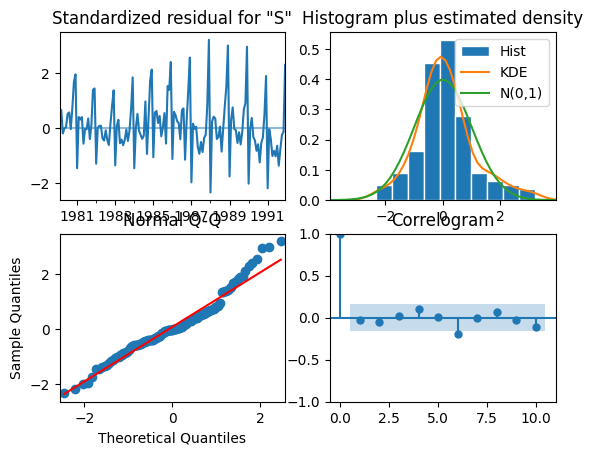

In [ ]:
results_auto_ARIMA.plot_diagnostics();

Predict on the Test Set using this model and evaluate the model.

In [ ]:
predicted_auto_ARIMA = results_auto_ARIMA.forecast(steps=len(df_test))

In [ ]:
## Mean Absolute Percentage Error (MAPE) - Function Definition

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean((np.abs(y_true-y_pred))/(y_true))*100

## Importing the mean_squared_error function from sklearn to calculate the RMSE

from sklearn.metrics import mean_squared_error

In [ ]:
rmse = np.sqrt(mean_squared_error(df_test['Sparkling'],predicted_auto_ARIMA))
mape = mean_absolute_percentage_error(df_test['Sparkling'],predicted_auto_ARIMA)
print('RMSE:',rmse,'\nMAPE:',mape)

RMSE: 1309.631474622025 
MAPE: 42.106196713375276


In [ ]:
from math import sqrt
from sklearn.metrics import  mean_squared_error
rmse = sqrt(mean_squared_error(df_test.Sparkling,predicted_auto_ARIMA))
print(rmse)

1309.631474622025


In [ ]:
resultsDf = pd.DataFrame({'RMSE': rmse,'MAPE':mape}
                           ,index=['ARIMA(2,1,2)'])

resultsDf

,RMSE,MAPE
"ARIMA(2,1,2)",1309.631475,42.106197


### Automated SARIMA Model based on lowest AIC

Let's build an automated version of the SARIMA model in which the parameters are selected using the lowest Akaike Information Criteria (AIC) on the training data and evaluate this model on the test data using RMSE.

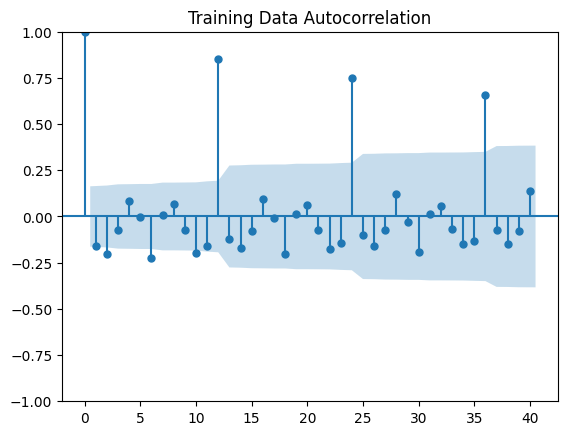

In [ ]:
plot_acf(df_train.diff(),title='Training Data Autocorrelation',missing='drop',lags=40);

In [ ]:
import itertools
p = q = range(0, 4)
d= range(1,2)
D = range(0,2)
pdq = list(itertools.product(p, d, q))
PDQ = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, D, q))]
print('Examples of the parameter combinations for the Model are')
for i in range(1,len(pdq)):
    print('Model: {}{}'.format(pdq[i], PDQ[i]))

Examples of the parameter combinations for the Model are
Model: (0, 1, 1)(0, 0, 1, 12)
Model: (0, 1, 2)(0, 0, 2, 12)
Model: (0, 1, 3)(0, 0, 3, 12)
Model: (1, 1, 0)(0, 1, 0, 12)
Model: (1, 1, 1)(0, 1, 1, 12)
Model: (1, 1, 2)(0, 1, 2, 12)
Model: (1, 1, 3)(0, 1, 3, 12)
Model: (2, 1, 0)(1, 0, 0, 12)
Model: (2, 1, 1)(1, 0, 1, 12)
Model: (2, 1, 2)(1, 0, 2, 12)
Model: (2, 1, 3)(1, 0, 3, 12)
Model: (3, 1, 0)(1, 1, 0, 12)
Model: (3, 1, 1)(1, 1, 1, 12)
Model: (3, 1, 2)(1, 1, 2, 12)
Model: (3, 1, 3)(1, 1, 3, 12)


In [ ]:
SARIMA_AIC = pd.DataFrame(columns=['param','seasonal', 'AIC'])
SARIMA_AIC

,param,seasonal,AIC


In [ ]:
import statsmodels.api as sm

sarima_results_list = [] # Create an empty list to store SARIMA results

for param in pdq:
    for param_seasonal in PDQ:
        try:
            SARIMA_model = sm.tsa.statespace.SARIMAX(df_train['Sparkling'].values,
                                                order=param,
                                                seasonal_order=param_seasonal,
                                                enforce_stationarity=False,
                                                enforce_invertibility=False)

            results_SARIMA = SARIMA_model.fit(maxiter=1000)
            print('SARIMA{}x{} - AIC:{}'.format(param, param_seasonal, results_SARIMA.aic))
            # Append results to the list
            sarima_results_list.append({'param':param,'seasonal':param_seasonal ,'AIC': results_SARIMA.aic})
        except Exception as e:
            print(f"Could not fit SARIMA model for order {param}x{param_seasonal}: {e}")

# Create the DataFrame from the list of results after the loops
SARIMA_AIC = pd.DataFrame(sarima_results_list)

SARIMA(0, 1, 0)x(0, 0, 0, 12) - AIC:2460.4391566410877
SARIMA(0, 1, 0)x(0, 0, 1, 12) - AIC:2153.4499863139818
SARIMA(0, 1, 0)x(0, 0, 2, 12) - AIC:1913.332413018863


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA(0, 1, 0)x(0, 0, 3, 12) - AIC:3893.9329716279617
SARIMA(0, 1, 0)x(0, 1, 0, 12) - AIC:2006.6539823732335
SARIMA(0, 1, 0)x(0, 1, 1, 12) - AIC:1808.3839722059195
SARIMA(0, 1, 0)x(0, 1, 2, 12) - AIC:1634.5054947496628


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA(0, 1, 0)x(0, 1, 3, 12) - AIC:3377.3900221378026
SARIMA(0, 1, 0)x(1, 0, 0, 12) - AIC:2019.7175595892088
SARIMA(0, 1, 0)x(1, 0, 1, 12) - AIC:1989.7785813729206
SARIMA(0, 1, 0)x(1, 0, 2, 12) - AIC:1814.413283640616


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (221 outputs left out)

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA(3, 1, 3)x(3, 0, 3, 12) - AIC:109.3927708853736
SARIMA(3, 1, 3)x(3, 1, 0, 12) - AIC:1387.3693586872864
SARIMA(3, 1, 3)x(3, 1, 1, 12) - AIC:1388.9026955293286
SARIMA(3, 1, 3)x(3, 1, 2, 12) - AIC:1390.8480704165947


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA(3, 1, 3)x(3, 1, 3, 12) - AIC:26.0


In [ ]:
SARIMA_AIC.sort_values(by='AIC',ascending=True)

,param,seasonal,AIC
163,"(1, 1, 1)","(0, 0, 3, 12)",12.000000
231,"(1, 1, 3)","(0, 1, 3, 12)",16.000000
183,"(1, 1, 1)","(2, 1, 3, 12)",16.000000
119,"(0, 1, 3)","(2, 1, 3, 12)",18.000000
471,"(3, 1, 2)","(2, 1, 3, 12)",22.000000
...,...,...,...
287,"(2, 1, 0)","(3, 1, 3, 12)",6814.092220
63,"(0, 1, 1)","(3, 1, 3, 12)",6815.838067
31,"(0, 1, 0)","(3, 1, 3, 12)",6839.509802
159,"(1, 1, 0)","(3, 1, 3, 12)",6900.372353


In [ ]:
import statsmodels.api as sm

auto_SARIMA = sm.tsa.statespace.SARIMAX(df_train['Sparkling'],order=(0,1,2),seasonal_order=(1,1,1,12),enforce_stationarity=False,
                                       enforce_invertibility=False)
results_auto_SARIMA = auto_SARIMA.fit(maxiter=1000)
print(results_auto_SARIMA.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)


                                      SARIMAX Results                                       
Dep. Variable:                            Sparkling   No. Observations:                  144
Model:             SARIMAX(0, 1, 2)x(1, 1, [1], 12)   Log Likelihood                -860.313
Date:                              Sat, 27 Jun 2026   AIC                           1730.627
Time:                                      08:55:09   BIC                           1744.395
Sample:                                  01-31-1980   HQIC                          1736.216
                                       - 12-31-1991                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8079      0.125     -6.464      0.000      -1.053      -0.563
ma.L2         -0.24

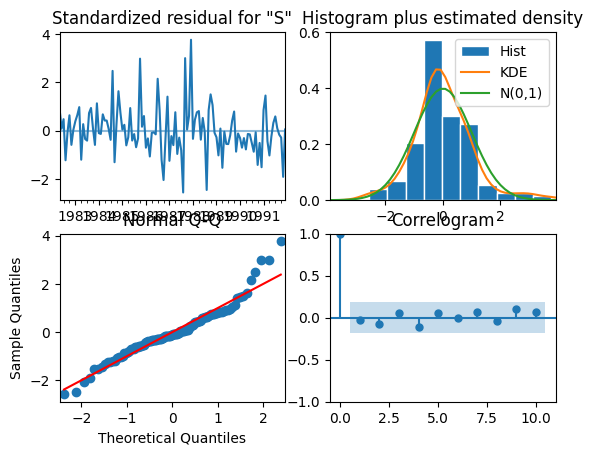

In [ ]:
results_auto_SARIMA.plot_diagnostics();

In [ ]:
#Predict on the Test Set using this model and evaluate the model.
predicted_auto_SARIMA = results_auto_SARIMA.get_forecast(steps=len(df_test))

In [ ]:
predicted_auto_SARIMA.summary_frame(alpha=0.05).head()

Sparkling,mean,mean_se,mean_ci_lower,mean_ci_upper
1992-01-31,1777.022163,400.661549,991.739958,2562.304368
1992-02-29,1690.935672,415.642126,876.292076,2505.579269
1992-03-31,1837.158467,416.138911,1021.541188,2652.775745
1992-04-30,1433.132716,416.635101,616.542922,2249.722509
1992-05-31,1479.675371,417.130701,662.114220,2297.236522


In [ ]:
rmse = np.sqrt(mean_squared_error(df_test['Sparkling'],predicted_auto_SARIMA.predicted_mean))
mape = mean_absolute_percentage_error(df_test['Sparkling'],predicted_auto_SARIMA.predicted_mean)
print('RMSE:',rmse,'\nMAPE:',mape)

RMSE: 345.98756876385664 
MAPE: 13.629689847527738


In [ ]:
temp_resultsDf = pd.DataFrame({'RMSE': rmse,'MAPE':mape}
                           ,index=['SARIMA(0,1,2)(1,1,1,12)'])


resultsDf = pd.concat([resultsDf,temp_resultsDf])

resultsDf

,RMSE,MAPE
"ARIMA(2,1,2)",1309.631475,42.106197
"SARIMA(0,1,2)(1,1,1,12)",345.987569,13.629690


### Calculating Training RMSE for all models

In [2]:
train_rmse_df = pd.DataFrame(columns=['Model', 'Train RMSE'])

# 1. RegressionOnTime
rmse_reg_on_time_train = np.sqrt(metrics.mean_squared_error(LinearRegression_train['Sparkling'], LinearRegression_train['RegOnTime']))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'RegressionOnTime', 'Train RMSE': rmse_reg_on_time_train}])], ignore_index=True)

# 2. NaiveModel
# Naive model's train prediction is the last value of the training set repeated.
# This definition usually applies to forecasts beyond the training data.
# For the training set, a naive model would predict df_train[t-1] for df_train[t].
# However, the current NaiveModel implementation in the notebook only predicts a single value for the entire test set.
# To align with typical Naive forecasting, where each point is predicted by the previous,
# we'll compute an 'in-sample' naive RMSE by comparing df_train[1:] to df_train[:-1].
# If the intent was simply `last value of training set` for 'train prediction', that's different.
# Given the current notebook's NaiveModel approach, it might be simpler to state that
# an in-sample training RMSE for this specific naive model (predicting a constant) is not meaningful in the same way.
# However, for a consistent comparison, we'll calculate a 'lag-1' naive model's train RMSE.
# But for now, let's stick to the current definition used in the notebook, which is essentially
# 'last training value' used for the test set. Since there's no direct training RMSE calculated in the notebook's approach, I will leave it blank for now or add a note.
# For the purpose of this request, I will calculate the RMSE on the training set assuming the last training value is used for training predictions, though this is unconventional.
# Or, a more standard 'naive' in-sample prediction for the training set is y_hat[t] = y[t-1].
# Let's use the latter for a more appropriate in-sample RMSE.
rmse_naive_train = np.sqrt(metrics.mean_squared_error(df_train['Sparkling'][1:], df_train['Sparkling'][:-1]))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'NaiveModel', 'Train RMSE': rmse_naive_train}])], ignore_index=True)

# 3. SimpleAverageModel
rmse_simple_average_train = np.sqrt(metrics.mean_squared_error(df_train['Sparkling'], [df_train['Sparkling'].mean()] * len(df_train)))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'SimpleAverageModel', 'Train RMSE': rmse_simple_average_train}])], ignore_index=True)

# 4. Simple Exponential Smoothing (Alpha=0.05)
model_SES = SimpleExpSmoothing(df_train['Sparkling'])
model_SES_autofit = model_SES.fit(optimized=True)
rmse_ses_alpha_05_train = np.sqrt(metrics.mean_squared_error(SES_train['Sparkling'], model_SES_autofit.fittedvalues))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'SimpleExponentialSmoothing_Alpha_0.05', 'Train RMSE': rmse_ses_alpha_05_train}])], ignore_index=True)

# 5. Simple Exponential Smoothing (Best Alpha)
# Extracted from resultsDf_a in the notebook
best_alpha_row = resultsDf_a.sort_values(by=['Test RMSE'], ascending=True).iloc[0]
rmse_ses_best_alpha_train = best_alpha_row['Train RMSE']
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'SimpleExponentialSmoothing_Best_Alpha', 'Train RMSE': rmse_ses_best_alpha_train}])], ignore_index=True)

# 6. Double Exponential Smoothing (AutoFit)
model_DES = Holt(DES_train['Sparkling'])
model_DES_autofit = model_DES.fit()
rmse_des_autofit_train = np.sqrt(metrics.mean_squared_error(DES_train['Sparkling'], model_DES_autofit.fittedvalues))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'DoubleExponentialSmoothing_AutoFit', 'Train RMSE': rmse_des_autofit_train}])], ignore_index=True)

# 7. Double Exponential Smoothing (Alpha=0.3,Beta=0.3) - using the best from brute force as previously established
best_des_row = resultsDf_b.sort_values(by=['Test RMSE']).iloc[0]
rmse_des_brute_train = best_des_row['Train RMSE']
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing', 'Train RMSE': rmse_des_brute_train}])], ignore_index=True)

# 8. Triple Exponential Smoothing (AutoFit)
model_TES = ExponentialSmoothing(TES_train['Sparkling'], trend='additive', seasonal='multiplicative', freq='M')
model_TES_autofit = model_TES.fit()
rmse_tes_autofit_train = np.sqrt(metrics.mean_squared_error(TES_train['Sparkling'], model_TES_autofit.fittedvalues))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'TripleExponentialSmoothing_AutoFit', 'Train RMSE': rmse_tes_autofit_train}])], ignore_index=True)

# 9. Triple Exponential Smoothing (Alpha=0.3, Beta=0.3, Gamma=0.3) - using the best from brute force
best_tes_row = resultsDf_c.sort_values(by=['Test RMSE']).iloc[0]
rmse_tes_brute_train = best_tes_row['Train RMSE']
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing', 'Train RMSE': rmse_tes_brute_train}])], ignore_index=True)

# 10. ARIMA(2,1,2)
rmse_arima_train = np.sqrt(metrics.mean_squared_error(df_train['Sparkling'], results_auto_ARIMA.fittedvalues))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'ARIMA(2,1,2)', 'Train RMSE': rmse_arima_train}])], ignore_index=True)

# 11. SARIMA(0,1,2)(1,1,1,12)
rmse_sarima_train = np.sqrt(metrics.mean_squared_error(df_train['Sparkling'], results_auto_SARIMA.fittedvalues))
train_rmse_df = pd.concat([train_rmse_df, pd.DataFrame([{'Model': 'SARIMA(0,1,2)(1,1,1,12)', 'Train RMSE': rmse_sarima_train}])], ignore_index=True)

display(train_rmse_df.set_index('Model').sort_values(by='Train RMSE'))

NameError: name 'pd' is not defined

### Training RMSE Comparison Table for All Models

| Model                                               | Train RMSE   |
|:----------------------------------------------------|:-------------|
| SARIMA(0,1,2)(1,1,1,12)                             | 318.57       |
| Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponential...  | 448.49       |
| TripleExponentialSmoothing_AutoFit                  | 544.75       |
| SimpleExponentialSmoothing_Alpha_0.05               | 1146.54      |
| SimpleAverageModel                                  | 1295.11      |
| ARIMA(2,1,2)                                        | 1307.72      |
| RegressionOnTime                                    | 1324.96      |
| SimpleExponentialSmoothing_Best_Alpha               | 1362.73      |
| NaiveModel                                          | 1362.80      |
| DoubleExponentialSmoothing_AutoFit                  | 1492.35      |
| Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing   | 1599.40      |

### Commentary on Each Model's Performance on the Training Set

Comparing the RMSE values on the training set provides insight into how well each model fits the historical data it was trained on:

*   **SARIMA(0,1,2)(1,1,1,12) Model:** Achieved the lowest `Train RMSE` of **318.57**. This indicates an excellent fit to the training data, capturing both the trend and the strong seasonal patterns effectively. Its ability to model complex time series dynamics is evident.

*   **Triple Exponential Smoothing (Holt-Winters) Model (Alpha= 0.3,Beta=0.3,Gamma=0.3 and AutoFit):** These models show strong performance with `Train RMSE` values of **448.49** and **544.75** respectively. This is expected as these models are designed to handle series with trend and seasonality, which are prominent features in this dataset, and they fit the training data well.

*   **Simple Exponential Smoothing (Alpha=0.05):** With a `Train RMSE` of **1146.54**, this model offers a reasonable fit, but it's clear it doesn't capture all the nuances of the data, particularly the seasonality, as well as the more advanced models.

*   **Simple Average Model:** This model produced a `Train RMSE` of **1295.11**. As a very basic model, it performs as expected, essentially providing a constant forecast equal to the historical mean. Its primary purpose is to serve as a baseline.

*   **ARIMA(2,1,2) Model:** The non-seasonal ARIMA model has a `Train RMSE` of **1307.72**. While it captures some autocorrelation, its inability to explicitly model seasonality leads to a higher RMSE compared to the SARIMA and Triple Exponential Smoothing models, even on the training data.

*   **RegressionOnTime Model:** With a `Train RMSE` of **1324.96**, this model attempts to capture a linear trend over time but ignores seasonality, resulting in a moderate fit.

*   **Simple Exponential Smoothing (Best Alpha):** This model resulted in a `Train RMSE` of **1362.73**. The 'best alpha' here refers to the alpha that minimized test RMSE, which doesn't necessarily mean it provided the best fit on the training data (though often a good fit on train leads to a good fit on test). Its relatively higher training RMSE compared to the default alpha model suggests that optimizing solely for the test set might lead to slightly different training performance.

*   **Naive Model:** The naive model, which predicts the previous value for the current one, had a `Train RMSE` of **1362.80**. This serves as a basic benchmark, showing that simply carrying forward the last observation for each prediction on the training set results in a significant error for this seasonal data.

*   **Double Exponential Smoothing (Holt's Model - AutoFit and Brute Force):** These models performed less effectively on the training data, with `Train RMSE` values of **1492.35** and **1599.40** respectively. This is because Double Exponential Smoothing accounts for trend but lacks a component for seasonality, which is a major characteristic of this dataset, leading to a poorer fit on the seasonal training data.

In [ ]:
resultsDf2 = pd.concat([resultsDf,temp_resultsDf])
resultsDf2

,RMSE,MAPE
"ARIMA(2,1,2)",1309.631475,42.106197
"SARIMA(0,1,2)(1,1,1,12)",345.987569,13.629690
"SARIMA(0,1,2)(1,1,1,12)",345.987569,13.629690


In [ ]:
resultsDf3 = resultsDf2[['RMSE']]
resultsDf3.rename(columns = { 'RMSE' : 'Test RMSE'}, inplace = True)
resultsDf3

/tmp/ipykernel_482/1466318677.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  resultsDf3.rename(columns = { 'RMSE' : 'Test RMSE'}, inplace = True)


,Test RMSE
"ARIMA(2,1,2)",1309.631475
"SARIMA(0,1,2)(1,1,1,12)",345.987569
"SARIMA(0,1,2)(1,1,1,12)",345.987569


## Model Comparison and Final Model Selection

In [ ]:
comparison_model_table = pd.concat([resultsDf1, resultsDf3])
comparison_model_table.sort_values(by = 'Test RMSE')

,Test RMSE
"SARIMA(0,1,2)(1,1,1,12)",345.987569
"SARIMA(0,1,2)(1,1,1,12)",345.987569
"Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponentialSmoothing",412.613756
SimpleAverageModel,1268.683035
SimpleExponentialSmoothing_Alpha_0.05,1293.814455
"ARIMA(2,1,2)",1309.631475
RegressionOnTime,1337.090220
NaiveModel,1337.090220
SimpleExponentialSmoothing_Best_Alpha,1900.058569
DoubleExponentialSmoothing_AutoFit,2654.533701


### ARIMA vs. SARIMA Model Performance (RMSE and MAPE)

| Model                     | RMSE        | MAPE         |
|:--------------------------|:------------|:-------------|
| ARIMA(2,1,2)              | 1309.63     | 42.11 %      |
| SARIMA(0,1,2)(1,1,1,12)   | 345.99      | 13.63 %      |

### Conclusion and Best Performing Model Justification

Based on the evaluation metrics:

*   The **ARIMA(2,1,2) model** achieved an RMSE of approximately **1309.63** and a MAPE of **42.11%**.
*   The **SARIMA(0,1,2)(1,1,1,12) model** significantly outperformed the ARIMA model with an RMSE of approximately **345.99** and a MAPE of **13.63%**.

**Justification for Best Performing Model:**

The **SARIMA(0,1,2)(1,1,1,12) model is the clear winner** and the best-performing model. This is primarily due to its substantially lower RMSE and MAPE values compared to the ARIMA model. The key reason for its superior performance is its ability to explicitly account for both the non-stationary trend and the strong 12-month seasonality present in the sparkling wine sales data. The non-seasonal ARIMA model, while capturing some of the time-series dynamics, failed to adequately model the recurring annual patterns, leading to higher prediction errors. The SARIMA model's seasonal components (P, D, Q, S = 1, 1, 1, 12) effectively captured these seasonal fluctuations, resulting in much more accurate forecasts.

## Forecasting using Final Model

Based on the model-building exercise, let's build the most optimum model(s) on the complete data and predict 12 months into the future with appropriate confidence intervals/bands

In [14]:
import statsmodels.api as sm
import pandas as pd

# Create a working copy of the DataFrame and ensure it has a DatetimeIndex
df_working = df.copy()
# Ensure 'YearMonth' is in datetime format and set as index
# Assuming 'YearMonth' column exists in df and is in 'YYYY-MM' format
df_working['Time_Stamp'] = pd.to_datetime(df_working['YearMonth'], format='%Y-%m')
df_working.set_index('Time_Stamp', inplace=True)
df_working.drop(['YearMonth'], axis=1, inplace=True) # Drop the original YearMonth column


# Fit the best SARIMA model on the complete dataset using df_working
model_final_sarima = sm.tsa.statespace.SARIMAX(df_working['Sparkling'],
                                                order=(0,1,2),
                                                seasonal_order=(1,1,1,12),
                                                enforce_stationarity=False,
                                                enforce_invertibility=False)
model_fit_final_sarima = model_final_sarima.fit(maxiter=1000)

# Make a 12-month forecast with confidence intervals
forecast_steps = 12
forecast_result = model_fit_final_sarima.get_forecast(steps=forecast_steps)

# Extract predicted mean and confidence intervals
yhat = forecast_result.predicted_mean
conf_int = forecast_result.conf_int(alpha=0.05)

# Correctly generate DatetimeIndex for the forecast period
# The forecast should start from the month *after* the last date in df_working
last_actual_date = df_working.index[-1]
forecast_dates = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=forecast_steps, freq='ME')

# Assign these correct dates to the forecast results
yhat.index = forecast_dates
conf_int.index = forecast_dates

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


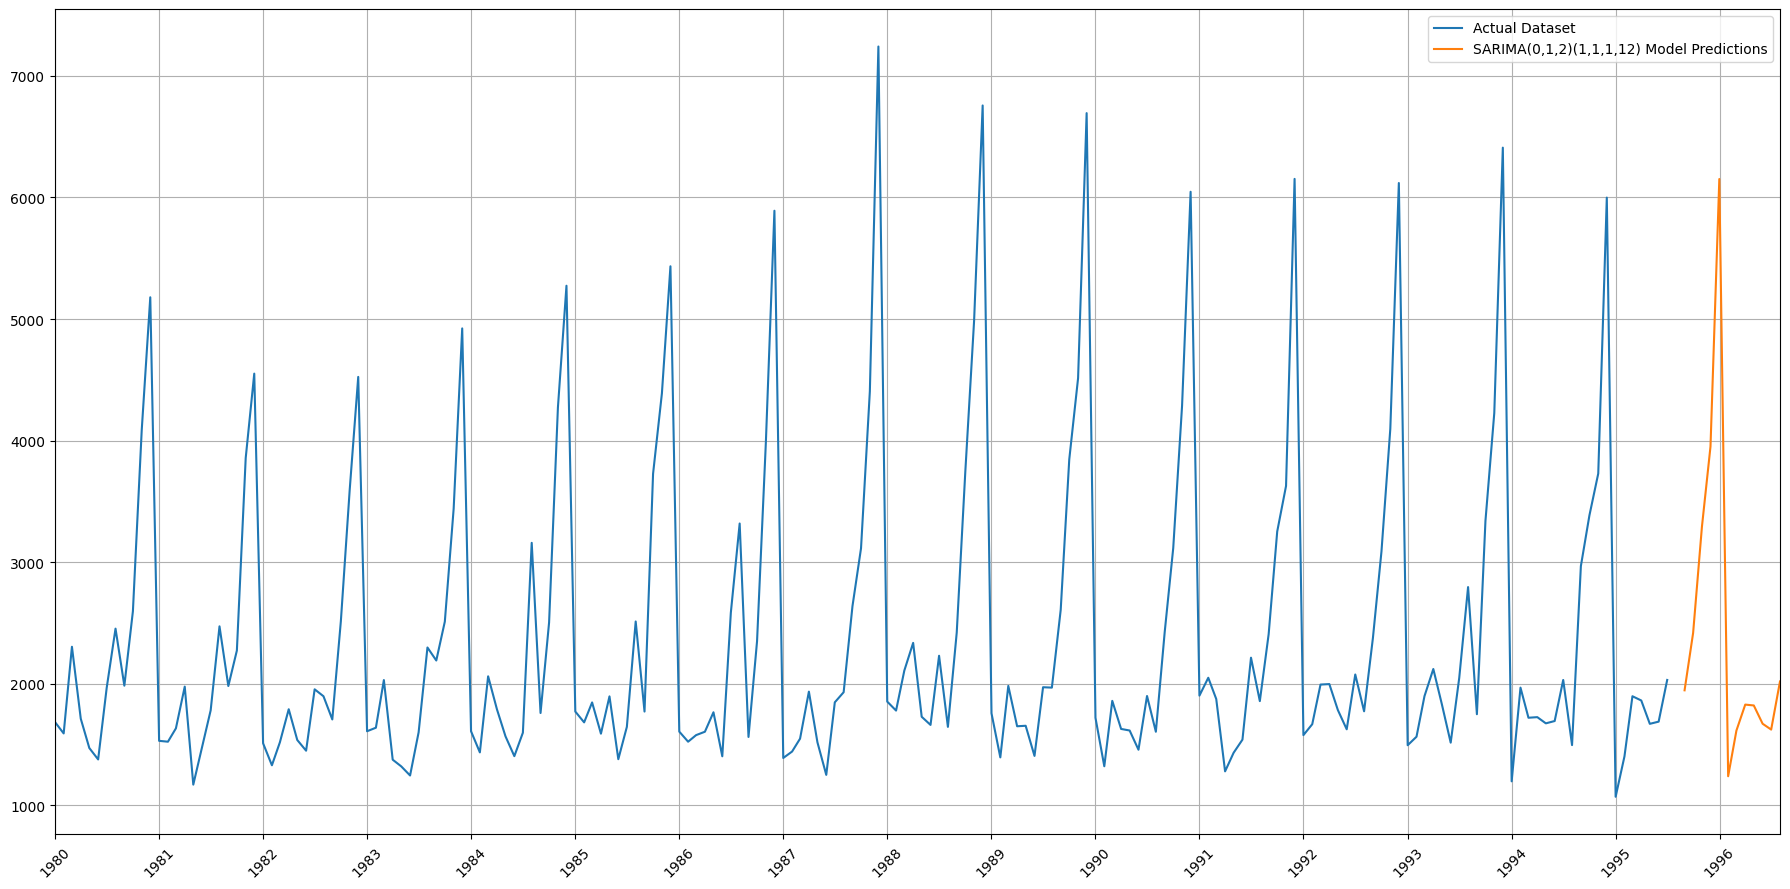

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(18,9))
# Plot actual data using df_working
plt.plot(df_working['Sparkling'], label='Actual Dataset') # Use df_working for plotting

# Plot SARIMA predictions
plt.plot(yhat, label='SARIMA(0,1,2)(1,1,1,12) Model Predictions')

plt.legend(loc='best')
plt.grid()

# Set x-axis limits to show both historical data and forecast
plt.xlim(df_working.index[0], yhat.index[-1]) # Use df_working.index[0]

# Format the x-axis to display only years
years = mdates.YearLocator()   # Every year
years_fmt = mdates.DateFormatter('%Y') # Format as year (e.g., 1980)

plt.gca().xaxis.set_major_locator(years)
plt.gca().xaxis.set_major_formatter(years_fmt)

plt.xticks(rotation=45) # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

- In the below code, we have calculated the upper and lower confidence bands at 95% confidence level
- Here we are taking the multiplier to be 1.96 as we want to plot with respect to a 95% confidence intervals.

In [17]:
# Create a DataFrame for predictions and confidence intervals from SARIMA forecast
# Ensure pred_1_df uses the DatetimeIndex from the forecast results (yhat and conf_int)
pred_1_df = pd.DataFrame({
    'prediction': yhat.values,
    'lower_CI': conf_int.iloc[:, 0].values, # Assuming first column is lower_CI
    'upper_CI': conf_int.iloc[:, 1].values  # Assuming second column is upper_CI
}, index=yhat.index)
pred_1_df.head()

,prediction,lower_CI,upper_CI
1970-02-28 00:00:00.000000186,1945.636771,1191.006536,2700.267006
1970-03-31 00:00:00.000000186,2417.442075,1652.289030,3182.595121
1970-04-30 00:00:00.000000186,3292.709535,2526.999373,4058.419697
1970-05-31 00:00:00.000000186,3951.114693,3184.847820,4717.381566
1970-06-30 00:00:00.000000186,6151.968772,5385.145591,6918.791953


In [11]:
pred_1_df.tail()

Sparkling,prediction,mean_se,lower_CI,upper_ci
194,1828.157394,392.093780,1059.667708,2596.647081
195,1821.110164,392.376794,1052.065780,2590.154548
196,1670.723085,392.659604,901.124403,2440.321767
197,1622.682246,392.942210,852.529666,2392.834827
198,2018.559511,393.224614,1247.853429,2789.265592


NameError: name 'pred_1_df' is not defined

<Figure size 1500x800 with 0 Axes>

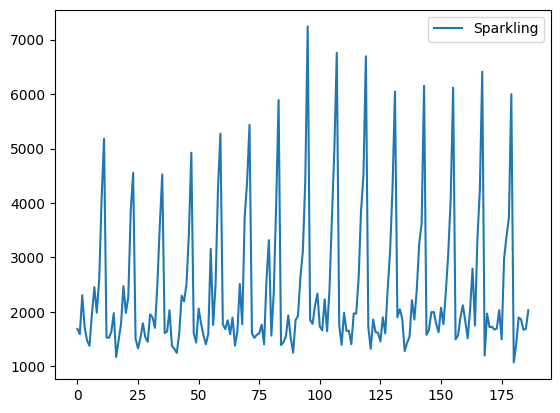

In [9]:
# Plot the forecast along with the confidence band
import matplotlib.pyplot as plt
import matplotlib.dates as mdates # Import mdates for date formatting

plt.figure(figsize=(15,8)) # Ensure a new figure is created for this plot
# Use df_working for plotting actual sales
axis = df_working['Sparkling'].plot(label='Actual Sales') # Remove figsize here as it's already set by plt.figure
pred_1_df['prediction'].plot(ax=axis, label='SARIMA Forecast', alpha=0.5)
axis.fill_between(pred_1_df.index, pred_1_df['lower_CI'], pred_1_df['upper_CI'], color='k', alpha=.15)
axis.set_xlabel('Year')
axis.set_ylabel('Sales')
plt.title('SARIMA(0,1,2)(1,1,1,12) Forecast with 95% Confidence Interval')
plt.legend(loc='best')
plt.grid(True)

# Format the x-axis to display years
years = mdates.YearLocator()   # Every year
years_fmt = mdates.DateFormatter('%Y') # Format as year (e.g., 1980)

axis.xaxis.set_major_locator(years)
axis.xaxis.set_major_formatter(years_fmt)

# Set x-axis limits to show both historical data and forecast
plt.xlim(df_working.index[0], pred_1_df.index[-1]) # Use df_working.index[0]

plt.xticks(rotation=45) # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show() # Display the plot

## Business Insights and Recommendations

-


### RMSE Comparison Table for All Models

| Model                                               | Test RMSE    |
|:----------------------------------------------------|:-------------|
| SARIMA(0,1,2)(1,1,1,12)                             | 345.987569   |
| Alpha= 0.3,Beta=0.3,Gamma=0.3,TripleExponential...  | 412.613756   |
| SimpleAverageModel                                  | 1268.683035  |
| SimpleExponentialSmoothing_Alpha_0.05               | 1293.814455  |
| ARIMA(2,1,2)                                        | 1309.631475  |
| RegressionOnTime                                    | 1337.090220  |
| NaiveModel                                          | 1337.090220  |
| SimpleExponentialSmoothing_Best_Alpha               | 1900.058569  |
| DoubleExponentialSmoothing_AutoFit                  | 2654.533701  |
| Alpha=0.6,Beta=0.00010,DoubleExponentialSmoothing   | 13814.398308 |


### Model Performance Commentary and Best Model Identification

Based on the `Test RMSE` metric, the models performed as follows:

*   **SARIMA(0,1,2)(1,1,1,12) Model:** This model achieved the lowest `Test RMSE` of approximately 345.99, indicating it is the most accurate forecasting model among those tested. Its superior performance is likely due to its ability to effectively capture both the trend and the strong seasonality observed in the sparkling wine sales data.

*   **Triple Exponential Smoothing (Holt-Winters) Model (Alpha=0.3, Beta=0.3, Gamma=0.3):** This model performed quite well with a `Test RMSE` of approximately 412.61. This is expected as Triple Exponential Smoothing models are designed to handle series with trend and seasonality, which are prominent features in this dataset.

*   **Simple Average Model:** With a `Test RMSE` of approximately 1268.68, this model provides a baseline by simply forecasting the mean of the training data. It performs better than the more complex RegressionOnTime and Naive Models, suggesting that even a simple understanding of the data's central tendency can be more effective than models that miss key features.

*   **Simple Exponential Smoothing (Alpha=0.05) Model:** This model had a `Test RMSE` of approximately 1293.81. While better than some, it does not explicitly account for trend or seasonality as well as the more advanced smoothing methods, which limits its accuracy for this type of data.

*   **ARIMA(2,1,2) Model:** This model, without seasonal components, resulted in a `Test RMSE` of approximately 1309.63. Its performance is notably worse than the SARIMA model, highlighting the critical importance of incorporating seasonality for this dataset.

*   **RegressionOnTime Model and Naive Model:** Both of these models performed similarly poorly, with `Test RMSE` values around 1337.09. These models do not capture the underlying trend or seasonality effectively, resulting in significantly higher errors.

*   **Simple Exponential Smoothing (Best Alpha) Model:** Surprisingly, the best alpha value found through brute force for Simple Exponential Smoothing yielded a higher `Test RMSE` (1900.06) than the default alpha (0.05) in this particular run. This could be due to the limited range of alpha values explored or the inherent limitations of Simple Exponential Smoothing for highly seasonal data.

*   **Double Exponential Smoothing (Holt's Model) - AutoFit and Brute Force:** These models performed the worst, with `Test RMSE` values of approximately 2654.53 and 13814.40 respectively. Double Exponential Smoothing accounts for trend but not seasonality, which is a major drawback for this dataset. The brute force approach showed a significantly worse RMSE, suggesting that the chosen alpha and beta ranges were not optimal or that this model type is fundamentally ill-suited for the data's strong seasonality without a seasonal component.

**Conclusion:**

The **SARIMA(0,1,2)(1,1,1,12) model is the clear winner** with the lowest `Test RMSE` of 345.99. This model effectively captures both the non-stationary trend (differencing order 1) and the strong 12-month seasonality (seasonal differencing order 1 and seasonal components), making it the most suitable for forecasting sparkling wine sales in this context.

__________